[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/notebooks/RO/capitol0_notebook_seminar.ipynb)

# Seminarul 0: Piețele financiare în 2026 — aplicații practice

**Modelarea Piețelor Financiare (MFM)**, programul de master *Statistică Aplicată și Data Science*, Academia de Studii Economice din București

*Daniel Traian Pele, Antoaneta Amza*

Pentru A9, A12, B4, B5, B6 extins și B10, cursul furnizează valori de referință: reproduceți-le cu propriul cod și interpretați eventualele diferențe. Exercițiile Seminarului 0, în ordinea slide-urilor seminarului ([slide-uri pentru studenți](https://danpele.github.io/MFM/EN/Seminars/seminar0_financial_markets.pdf)). Seminarul are loc înaintea cursului din Capitolul 0: fiecare noțiune din partea de bază este definită în enunțul exercițiului în care apare.

- **Partea de bază** (la seminar): [Verificarea configurației](#setup), [A1–A4](#A1), [B1](#B1), [B2](#B2)
- **Rîndul vostru** (la seminar): [A5](#A5), [A6](#A6)
- **Temă pentru acasă**: [B3](#B3), [B4](#B4), [B5](#B5), [C1](#C1)
- **După curs (opțional)**, fiecare pachet în ordinea dependențelor sale: [Pachetul 1](#pack1) (B1 audit complet, B2 șase active, B6), [Pachetul 2](#pack2) (A7, B2 extins), [Pachetul 3](#pack3) (A8, A9, A10), [Pachetul 4](#pack4) (B6 extins, A11, A12, C2), [Pachetul 5](#pack5) (B5 extins), [Pachetul 6](#pack6) (B7, B8, B9, B9 extins, B1 extins), [Pachetul 7](#pack7) (B10, B10 extins), [Pachetul 8](#pack8) (C3)

Exercițiile **[Rezolvat]** prezintă codul complet și rezultatele: folosiți-le ca modele. Exercițiile **[Propus]** au o celulă goală: scrieți acolo codul (sau răspunsul). Funcțiile care citesc datele, precum și funcțiile auxiliare, sînt furnizate. Fiecare exercițiu cu bootstrap își creează propriul generator `numpy.random.default_rng(42)`, astfel încît rezultatele sale nu depind de celulele pe care le-ați rulat anterior.

## Configurare <a id="setup"></a>

> **Lucrați în Google Colab? Salvați mai întîi propria copie.**
> Linkul Colab deschide o copie temporară: cînd închideți fila sau cînd sesiunea expiră, modificările se pierd.
> Folosiți **File → Save a copy in Drive** (copia ajunge în folderul *Colab Notebooks* din Google Drive-ul vostru ASE) și lucrați în acea copie.
> Pentru proiectul de echipă, **File → Save a copy in GitHub** pune notebook-ul direct în repository-ul echipei.
> Fișierele create în timpul rulării notebook-ului (CSV, grafice) sînt și ele temporare: setați `SAVE_TO_DRIVE = True` în celula următoare pentru a le păstra.

In [ ]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/MFM/Chapter_0'
    os.makedirs(OUT_DIR, exist_ok=True)
print('Save your outputs to:', os.path.abspath(OUT_DIR))


Save your outputs to: /content/mfm-audit/20261016T140807-fe4af1


In [ ]:
import os
import io
import json
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

In [ ]:
# Chart style: transparent background, legend below the plot
plt.rcParams['figure.facecolor'] = 'none'
plt.rcParams['axes.facecolor'] = 'none'
plt.rcParams['savefig.facecolor'] = 'none'
plt.rcParams['savefig.transparent'] = True
plt.rcParams['axes.grid'] = False
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 9
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.linewidth'] = 0.6
plt.rcParams['lines.linewidth'] = 1.1
plt.rcParams['legend.facecolor'] = 'none'
plt.rcParams['legend.framealpha'] = 0
plt.rcParams['legend.fontsize'] = 8

# Chart colours
MainBlue = '#1A3A6E'
IDAred   = '#CD0000'
Forest   = '#2E7D32'
Amber    = '#B5853F'
Orange   = '#E67E22'
Purple   = '#8E44AD'
Crimson  = '#DC3545'
Navy     = '#1F2A44'   # reference lines (no grey in charts)
BandBlue = '#C5D2E8'   # light MainBlue tint for confidence / reference bands
Gray, LightGray = Navy, BandBlue   # legacy names kept for importing scripts
Teal     = '#17A2B8'


def save_fig(name):
    """Show the chart inline"""
    plt.show()
    plt.close()


def legend_outside_bottom(ax, ncol=2, y=-0.22):
    """Place the legend outside the plot, bottom centre."""
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, y), ncol=ncol, frameon=False)


def bottom_legend(fig, ncol=3, handles=None, labels=None, fontsize=8):
    """Legend below the figure (outside the axes), after tight_layout; save_fig keeps it (bbox_inches='tight')."""
    plt.tight_layout()
    if handles is None:
        handles, labels, seen = [], [], set()
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in seen and not l.startswith('_'):
                    handles.append(h); labels.append(l); seen.add(l)
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=ncol, frameon=False, fontsize=fontsize)


def log_axis(ax, ticks):
    """Log axis with readable labels (no scientific notation)."""
    ax.set_yscale('log')
    ax.set_yticks(ticks)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:g}'))
    ax.yaxis.set_minor_formatter(plt.NullFormatter())

In [ ]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
LOCAL_DIRS = ['../../data/market', '../data/market', 'data/market']   # cloned repository
START, END = '2000-01-01', '2026-09-18'

# name -> (source, symbol, field)
SERIES = {
    'S&P 500': ('market', 'GSPC.INDX', 'close'),
    'Euro Stoxx 50': ('market', 'STOXX50E.INDX', 'close'),
    'Nikkei 225': ('market', 'N225.INDX', 'close'),
    'VIX': ('market', 'VIX.INDX', 'close'),
    'BET-TR': ('market', 'BETTR.INDX', 'close'),
    'BET': ('market', 'BET', 'close'),
    'BET-XT': ('market', 'BETXT.INDX', 'close'),
    'US Treasuries 20y+ (TLT)': ('market', 'TLT.US', 'adjusted_close'),
    'SPY': ('market', 'SPY.US', 'adjusted_close'),
    'RSP': ('market', 'RSP.US', 'adjusted_close'),
    'IBIT': ('market', 'IBIT.US', 'close'),
    'IBIT volume': ('market', 'IBIT.US', 'volume'),
    'Gold': ('market', 'XAUUSD.FOREX', 'close'),
    'EUR/USD': ('market', 'EURUSD.FOREX', 'close'),
    'EUR/RON (market)': ('market', 'EURRON.FOREX', 'close'),
    'Bitcoin': ('market', 'BTC-USD.CC', 'close'),
    'Ethereum': ('market', 'ETH-USD.CC', 'close'),
    'Tether (USDT)': ('market', 'USDT-USD.CC', 'close'),
    'Romania 10y': ('market', 'RO10Y.GBOND', 'close'),
    'Germany 10y': ('market', 'DE10Y.GBOND', 'close'),
    'Banca Transilvania': ('market', 'TLV.RO', 'adjusted_close'),
    'OMV Petrom': ('market', 'SNP.RO', 'adjusted_close'),
    'BRD': ('market', 'BRD.RO', 'adjusted_close'),
    'Transgaz': ('market', 'TGN.RO', 'adjusted_close'),
    'Romgaz': ('market', 'SNG.RO', 'adjusted_close'),
    'Hidroelectrica': ('market', 'H2O.RO', 'adjusted_close'),
    'EUR/RON': ('bnr', 'EUR', None),
    'DGS10': ('fred', 'DGS10', None),
    'DGS2': ('fred', 'DGS2', None),
    'FEDFUNDS': ('fred', 'FEDFUNDS', None),
    'USD per EUR': ('fred', 'DEXUSEU', None),
    'JPY per USD': ('fred', 'DEXJPUS', None),
    'T10Y2Y': ('fred', 'T10Y2Y', None),
    'ETF equities': ('fred', 'BOGZ1LM563064100Q', None),
    'All equities': ('fred', 'BOGZ1LM893064105Q', None),
    'Stablecoins': ('defillama', 'stablecoincharts/all', None),
}


def read_market(symbol):
    """Daily market series: local copy if the repository is cloned, otherwise GitHub"""
    for d in LOCAL_DIRS:
        path = os.path.join(d, f'{symbol}.csv')
        if os.path.exists(path):
            return pd.read_csv(path, index_col='date', parse_dates=True)
    return pd.read_csv(REPO_RAW + f'{symbol}.csv', index_col='date', parse_dates=True)


def fetch_daily(symbol, source='market', field='close', start=START, end=END):
    """Single access point to the data: returns a daily pd.Series (no NaN)."""
    if source == 'market':
        s = read_market(symbol)[field]
    elif source == 'fred':
        raw = urllib.request.urlopen(
            f'https://fred.stlouisfed.org/graph/fredgraph.csv?id={symbol}', timeout=90).read().decode()
        s = pd.read_csv(io.StringIO(raw), index_col=0, parse_dates=True, na_values='.').iloc[:, 0]
    elif source == 'defillama':
        req = urllib.request.Request(f'https://stablecoins.llama.fi/{symbol}',
                                     headers={'User-Agent': 'Mozilla/5.0'})
        d = json.load(urllib.request.urlopen(req, timeout=90))
        s = pd.Series({pd.to_datetime(int(x['date']), unit='s'): x['totalCirculatingUSD'].get('peggedUSD', 0)
                       for x in d}) / 1e9                                   # billion USD
    elif source == 'bnr':
        # official BNR rate (RON per unit of currency), yearly XML archives
        import re
        rows = []
        for y in range(max(int(start[:4]), 2005), int(end[:4]) + 1):
            url = f'https://curs.bnr.ro/files/xml/years/nbrfxrates{y}.xml'
            xml = urllib.request.urlopen(urllib.request.Request(url, headers={'User-Agent': 'Mozilla'}),
                                         timeout=90).read().decode()
            for d, body in re.findall(r'<Cube date="([\d-]+)">(.*?)</Cube>', xml, re.S):
                m = re.search(rf'<Rate currency="{symbol}">([\d.]+)</Rate>', body)
                if m:
                    rows.append((d, float(m.group(1))))
        s = pd.Series(dict(rows))
    else:
        raise ValueError(f'unknown source: {source}')
    s = pd.to_numeric(s, errors='coerce')
    s.index = pd.to_datetime(s.index)
    s.index.name = 'Date'
    return s.sort_index().loc[start:end].dropna()


WEEKDAYS_ONLY = {'EUR/USD', 'Gold'}   # FX/OTC quotes: weekend quotes break the Friday-Monday return


def load(name, start=START, end=END):
    """The series named in SERIES (gold and EUR/USD: weekdays only)."""
    source, symbol, field = SERIES[name]
    s = fetch_daily(symbol, source, field, start, end).rename(name)
    if name in WEEKDAYS_ONLY:
        s = s[s.index.dayofweek < 5]
    return s


def load_panel(names, start=START, end=END):
    """Several series aligned on date (NaN where a market does not trade)."""
    return pd.concat([load(n, start, end) for n in names], axis=1)

In [ ]:
def clean_series(y, max_dev=1.0, window=11):
    """Drop weekend rows and points more than max_dev from the centred rolling median."""
    y = y[y.index.dayofweek < 5]
    med = y.rolling(window, center=True, min_periods=3).median()
    return y[(y - med).abs() <= max_dev]


def drawdown(p):
    """Drawdown from the previous peak: P_t / max_{s<=t} P_s - 1."""
    return p / p.cummax() - 1


def ann_stats(p, periods=252):
    """Annualised return (CAGR) and annualised volatility from daily prices.

    periods='obs' uses the observed number of observations per year of the series.
    """
    p = p.dropna()
    years = (p.index[-1] - p.index[0]).days / 365.25
    cagr = (p.iloc[-1] / p.iloc[0]) ** (1 / years) - 1
    r = np.log(p).diff().dropna()
    if periods == 'obs':
        periods = len(r) / years
    return cagr, r.std() * np.sqrt(periods)


def to_usd(local, fx, invert=False):
    """Convert a local-currency index to USD with the FRED rate of the same day
    (the last available rate, at most 5 days back, if the day is missing)."""
    f = fx.dropna().reindex(local.index, method='ffill', tolerance=pd.Timedelta(days=5))
    return (local / f if invert else local * f).dropna()

In [ ]:
def sb_index(n, mean_block, rng):
    """Stationary bootstrap (Politis and Romano, 1994): blocks of random, geometric length with mean mean_block, wrapped around."""
    idx = np.empty(n, dtype=int); i = rng.integers(n)
    for t in range(n):
        i = rng.integers(n) if (t == 0 or rng.random() < 1 / mean_block) else (i + 1) % n
        idx[t] = i
    return idx


def obs_per_year(p):
    """Observed return intervals per year q = n / Y: n returns, Y = calendar days between first and last price / 365.25."""
    return (len(p) - 1) / ((p.index[-1] - p.index[0]).days / 365.25)


def sharpe(R, q):
    """Annualised Sharpe ratio, r_f = 0: sample mean / sample sd (divisor n - 1) of simple returns R, times sqrt(q)."""
    return R.mean() / R.std(ddof=1) * np.sqrt(q)


def se_lo(R, q):
    """Lo (2002), iid Normal returns, asymptotic: SE of the annualised Sharpe from T daily returns, sqrt(q (1 + SR_d^2/2) / T)."""
    sr_d = R.mean() / R.std(ddof=1)
    return np.sqrt(q * (1 + sr_d ** 2 / 2) / len(R))


def se_opdyke(R, q):
    """Opdyke (2007): asymptotic SE of the annualised Sharpe corrected for the skewness and kurtosis of daily returns."""
    from scipy import stats
    sr = R.mean() / R.std(ddof=1); g3 = stats.skew(R); g4 = stats.kurtosis(R, fisher=False)
    return np.sqrt((1 + sr ** 2 / 2 - g3 * sr + (g4 - 3) / 4 * sr ** 2) / len(R)) * np.sqrt(q)

**Verificarea configurației.** `load(name, start)` citește o serie zilnică după numele ei (dicționarul `SERIES` listează fiecare nume și cîmpul său de preț). Prețul de închidere ajustat (adjusted close) al SPY de la 2 ian. 2015 trebuie să aibă 2,945 de prețuri, de la 2 ian. 2015 pînă la 18 sep. 2026; primul adjusted close este 169.26, iar prețul de închidere (close) 205.43 (dividendele sînt incluse doar în adjusted close). Cursul BNR EUR/RON are 2,939 de valori, iar seria EUR/RON de la EODHD 3,115, de la 1 ian. 2015. Dacă rezultatul vostru diferă, opriți-vă și verificați numele și data de început.

In [ ]:
spy = load('SPY', start='2015-01-02')
bnr = load('EUR/RON', start='2015-01-01')
mkt = load('EUR/RON (market)', start='2015-01-01')
print(len(spy), spy.index[0].date(), spy.index[-1].date())
print(len(bnr), len(mkt))
print(read_market('SPY.US').loc['2015-01-02':'2015-01-06', ['close', 'adjusted_close']].round(2))

2945 2015-01-02 2026-09-18
2939 3115
             close  adjusted_close
date                              
2015-01-02  205.43          169.26
2015-01-05  201.76          166.24
2015-01-06  199.82          164.64


## Partea de bază (la seminar)

### A1–A4 [Rezolvat]. Randamente, anualizare, CAGR și drawdown <a id="A1"></a>

**A1.** Prețurile $P_0 = 100$, $P_1 = 110$, $P_2 = 99$. (1) Calculați randamentele simple $R_1, R_2$ și randamentele logaritmice $r_1, r_2$. (2) Adunați cele două randamente simple și cele două randamente logaritmice. (3) Calculați randamentele pe două perioade $P_2/P_0 - 1$ și $\ln(P_2/P_0)$ și comparați-le cu sumele. **Raportați:** un tabel dată / preț / randament simplu / randament logaritmic și o propoziție despre care randamente se adună.

**A2.** Volatilitatea zilnică $\sigma_d = 1\%$: (1) anualizați cu $q = 252$ (indice bursier) și cu $q = 365$ (Bitcoin); (2) enunțați cele două ipoteze în care scalarea cu $\sqrt{q}$ este exactă.

**A3.** Indicele de preț S&P 500 s-a multiplicat de 3.72 ori între 2 ian. 2015 și 18 sep. 2026 (4,277 de zile calendaristice): (3) calculați $Y = 4277/365.25$ și CAGR $= 3.72^{1/Y} - 1$; (4) explicați de ce este mai mic decît valoarea de 13.7% a SPY din B2.

**A4.** Prețurile în zilele 0–5: 100, 120, 90, 110, 130, 100. (1) Maximul cumulat (running peak) $M_t = \max_{s \le t} P_s$. (2) Drawdown-ul $DD_t = P_t/M_t - 1$. (3) Drawdown-ul maxim $\min_t DD_t$ și ziua în care apare. **Raportați:** tabelul completat și drawdown-ul maxim.

In [ ]:
P = np.array([100, 110, 99]); R = P[1:] / P[:-1] - 1; r = np.log(P[1:] / P[:-1])
print(pd.DataFrame({'price': P, 'simple return': np.r_[np.nan, R], 'log return': np.r_[np.nan, r]}).round(4))
print(f'A1: sum of simple returns {R.sum():+.4f}, compounded {(1 + R).prod() - 1:+.4f}; sum of log returns {r.sum():+.5f} = ln(0.99) {np.log(0.99):+.5f}')
print('A2:', round(0.01 * np.sqrt(252), 4), round(0.01 * np.sqrt(365), 4), '(exact if daily returns are uncorrelated with constant variance)')
Y = 4277 / 365.25; print(f'A3: Y = {Y:.2f}, CAGR = {3.72 ** (1 / Y) - 1:.2%} (price index: no dividends)')
P = pd.Series([100, 120, 90, 110, 130, 100]); M_ = P.cummax()
print(pd.DataFrame({'P': P, 'M': M_, 'DD': (P / M_ - 1).round(4)}).T)
print('A4: maximum drawdown', round(float(drawdown(P).min()), 4), 'on day', int(drawdown(P).idxmin()))

   price  simple return  log return
0    100            NaN         NaN
1    110            0.1      0.0953
2     99           -0.1     -0.1054
A1: sum of simple returns +0.0000, compounded -0.0100; sum of log returns -0.01005 = ln(0.99) -0.01005
A2: 0.1587 0.191 (exact if daily returns are uncorrelated with constant variance)
A3: Y = 11.71, CAGR = 11.87% (price index: no dividends)
        0      1       2         3      4         5
P   100.0  120.0   90.00  110.0000  130.0  100.0000
M   100.0  120.0  120.00  120.0000  130.0  130.0000
DD    0.0    0.0   -0.25   -0.0833    0.0   -0.2308
A4: maximum drawdown -0.25 on day 2


### B1 [Rezolvat]. O cotație suspectă <a id="B1"></a>

Un **bad tick** este un preț înregistrat la care nu a tranzacționat nimeni (o greșeală de tastare, o zecimală greșită, o cotație a altui instrument). **Cursul de referință BNR** este cursul oficial EUR/RON, publicat în fiecare zi lucrătoare din România în jurul orei 13:00. Trei semne ale unui bad tick: (1) o variație într-o zi mult mai mare decît de obicei, (2) inversată a doua zi, (3) departe de o sursă independentă din aceeași zi.

**Întrebare.** Este cotația de piață EUR/RON din 13 aug. 2025 un preț real?

**Date.** Seria EUR/RON de la EODHD (close), 1 ian. 2015 – 18 sep. 2026, 3,115 rînduri; cursul de referință BNR.

**Cerințe.**
1. Calculați variațiile logaritmice zilnice ale seriei de piață și găsiți-o pe cea mai mare în valoare absolută.
2. Pentru 13 aug. 2025, raportați cotația anterioară, cotația și cotația următoare, precum și cele două variații logaritmice.
3. Comparați cotația cu cursul BNR din 13 aug. 2025, în RON și în procente.
4. Calculați volatilitatea anualizată a seriei de piață, a aceleiași serii fără această cotație și a cursului BNR, fiecare cu propriul $q$.

**Raportați:** cele trei cotații, diferența față de BNR și cele trei volatilități. **Interpretare:** care dintre cele trei semne sînt prezente?

1. largest |log change|: -15.41% on 2025-08-14
2. 2025-08-12 5.0636 -> 2025-08-13 5.9065 -> 2025-08-14 5.0629; log changes +15.40%, -15.41%
3. BNR 5.0633; gap 0.8432 RON (+16.7%)
4. market series 12.4% (q = 265.9); without 13 Aug 2025 10.6%; BNR 2.1% (q = 251.1)


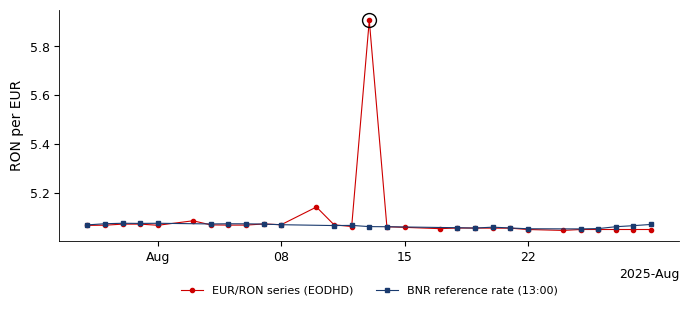

In [ ]:
m = load('EUR/RON (market)', start='2015-01-01'); bnr = load('EUR/RON', start='2015-01-01')
vol = lambda x: np.log(x).diff().dropna().std() * np.sqrt(obs_per_year(x))      # each series with its own q
r = np.log(m).diff().dropna()
print(f'1. largest |log change|: {r[r.abs().idxmax()]:+.2%} on {r.abs().idxmax().date()}')
d = pd.Timestamp('2025-08-13'); i = m.index.get_loc(d); prev, nxt = m.index[i - 1], m.index[i + 1]
print(f'2. {prev.date()} {m[prev]:.4f} -> {d.date()} {m[d]:.4f} -> {nxt.date()} {m[nxt]:.4f}; '
      f'log changes {np.log(m[d] / m[prev]):+.2%}, {np.log(m[nxt] / m[d]):+.2%}')
print(f'3. BNR {bnr[d]:.4f}; gap {m[d] - bnr[d]:.4f} RON ({m[d] / bnr[d] - 1:+.1%})')
print(f'4. market series {vol(m):.1%} (q = {obs_per_year(m):.1f}); without 13 Aug 2025 {vol(m.drop(d)):.1%}; '
      f'BNR {vol(bnr):.1%} (q = {obs_per_year(bnr):.1f})')
a, b = '2025-07-28', '2025-08-29'
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(m.loc[a:b].index, m.loc[a:b], 'o-', color=IDAred, lw=0.8, ms=3, label='EUR/RON series (EODHD)')
ax.plot(bnr.loc[a:b].index, bnr.loc[a:b], 's-', color=MainBlue, lw=0.8, ms=3, label='BNR reference rate (13:00)')
ax.plot(d, m[d], 'o', ms=10, mfc='none', mec='black'); ax.set_ylabel('RON per EUR')
import matplotlib.dates as mdates
date_locator = mdates.AutoDateLocator(minticks=4, maxticks=6)
ax.xaxis.set_major_locator(date_locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(date_locator))
legend_outside_bottom(ax, ncol=2, y=-0.15); plt.show()

**Interpretare (soluție).** Toate cele trei semne sînt prezente: o variație de 15% acolo unde cursul BNR se mișcă cu aproximativ 0.13% pe zi, inversată a doua zi, la 0.84 RON distanță de BNR: un bad tick. O singură cotație adaugă 1.8 pp la volatilitatea anualizată; seria de piață este în continuare de cinci ori mai volatilă decît cursul BNR, deci rămîn și alte bad ticks (B1 audit complet, Pachetul 1).

### B2 [Rezolvat]. Trei active pe un singur grafic <a id="B2"></a>

**Creșterea unui USD** $G_t = P_t/P_0$ este valoarea în ziua $t$ a unui USD investit în ziua 0. Pe o **scală logaritmică**, distanțele egale corespund unor rapoarte egale (1 → 2 are aceeași înălțime ca 100 → 200), iar o rată de creștere constantă apare ca o linie dreaptă. **Drawdown** $DD_t = P_t/M_t - 1$, cu maximul cumulat (running peak) $M_t = \max_{s \le t} P_s$; drawdown-ul maxim (MDD) este $\min_t DD_t$.

**Întrebări.**
- Cît a crescut 1 USD investit în SPY, aur și Bitcoin din 2015?
- Cît de volatil a fost fiecare?
- Cît de adîncă a fost cea mai mare cădere?

**Date.** SPY (adjusted close), aur (close, zile lucrătoare), Bitcoin (close, în fiecare zi), 2 ian. 2015 – 18 sep. 2026, toate în USD; fiecare activ pe propriul calendar.

**Cerințe.**
1. Reprezentați grafic creșterea unui USD, $P_t/P_0$, pe scală logaritmică.
2. Pentru fiecare activ calculați multiplul, $Y$ și CAGR.
3. Calculați $n$, $q = n/Y$, volatilitatea zilnică $\hat\sigma_d$ și volatilitatea anualizată $\hat\sigma_d\sqrt{q}$.
4. Reprezentați grafic curbele de drawdown și raportați fiecare drawdown maxim cu datele vîrfului (peak) și ale minimului (trough).

**Raportați:** cele două grafice și un tabel (multiplu, CAGR, $q$, volatilitate, MDD). **Interpretare:** activul cu cel mai mare CAGR are și cea mai mare volatilitate și cel mai adînc drawdown?

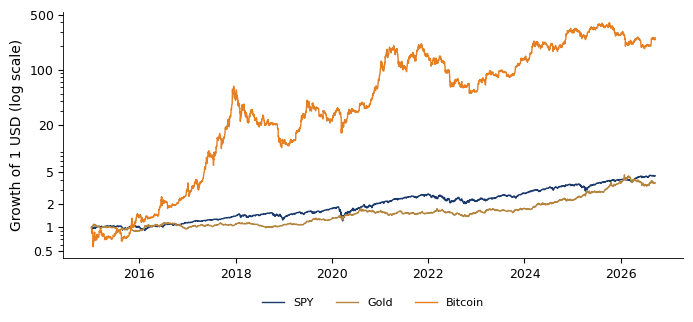

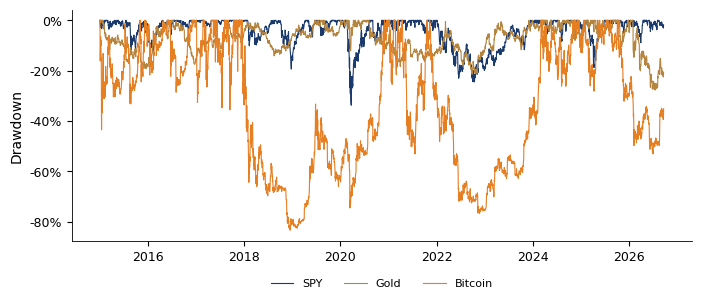

            n      Y  multiple    CAGR         q  daily vol     vol     MDD        peak      trough  DD now
asset                                                                                                      
SPY      2944  11.71    4.5000  0.1371  251.4136     0.0111  0.1756 -0.3372  2020-02-19  2020-03-23 -0.0184
Gold     3050  11.71    3.6832  0.1178  260.4659     0.0101  0.1633 -0.2770  2026-01-28  2026-07-16 -0.2055
Bitcoin  4277  11.71  256.8039  0.6061  365.2500     0.0349  0.6668 -0.8340  2017-12-16  2018-12-15 -0.3515


In [ ]:
def core_table(prices):
    """Multiple, CAGR, q, annualised volatility and maximum drawdown of each price series, on its own calendar."""
    rows = []
    for n, p in prices.items():
        Y = (p.index[-1] - p.index[0]).days / 365.25; r = np.log(p).diff().dropna(); q = obs_per_year(p)
        dd = drawdown(p); tr = dd.idxmin(); pk = p.loc[:tr].idxmax()
        rows.append((n, len(r), round(Y, 2), p.iloc[-1] / p.iloc[0], (p.iloc[-1] / p.iloc[0]) ** (1 / Y) - 1, q,
                     r.std(), r.std() * np.sqrt(q), dd.min(), pk.date(), tr.date(), dd.iloc[-1]))
    return pd.DataFrame(rows, columns=['asset', 'n', 'Y', 'multiple', 'CAGR', 'q', 'daily vol', 'vol', 'MDD', 'peak',
                                       'trough', 'DD now']).set_index('asset')


def growth_and_drawdown_charts(prices, cols, ticks):
    fig, ax = plt.subplots(figsize=(8, 3.2))
    for n, p in prices.items():
        ax.plot(p.index, p / p.iloc[0], color=cols[n], lw=1.0, label=n)
    log_axis(ax, ticks); ax.set_ylabel('Growth of 1 USD (log scale)'); legend_outside_bottom(ax, ncol=3, y=-0.12); plt.show()
    fig, ax = plt.subplots(figsize=(8, 3))
    for n, p in prices.items():
        dd = drawdown(p); ax.plot(dd.index, dd, color=cols[n], lw=0.8, label=n)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}')); ax.set_ylabel('Drawdown')
    legend_outside_bottom(ax, ncol=3, y=-0.12); plt.show()


three = {'SPY': load('SPY', start='2015-01-02'), 'Gold': load('Gold', start='2015-01-02'),
         'Bitcoin': load('Bitcoin', start='2015-01-02')}
growth_and_drawdown_charts(three, {'SPY': MainBlue, 'Gold': Amber, 'Bitcoin': Orange}, [0.5, 1, 2, 5, 20, 100, 500])
print(core_table(three).round(4).to_string())

**Interpretare (soluție).** Da, în acest eșantion: Bitcoin are cel mai mare CAGR (60.6%), o volatilitate de aproximativ patru ori mai mare decît a SPY și a aurului (66.7% față de 17.6% și 16.3%) și cel mai adînc drawdown (−83.4%, dec. 2017 – dec. 2018). SPY și aurul au volatilități similare; cea mai mare cădere a aurului (−27.7%, ian. – iul. 2026) este recentă și încă nu a fost recuperată. Este un singur eșantion de 11.7 ani: dacă astfel de diferențe sînt de încredere este subiectul cursului și al Pachetului 2.

## Rîndul vostru (la seminar)

### A5 [Propus]. Randamente, CAGR și volatilitate <a id="A5"></a>

**Model:** A1 și A2–A3 [Rezolvat]. **Date de intrare:** o acțiune cu $P_0 = 50$, $P_1 = 55$, $P_2 = 44$; un fond care a crescut de la 100 la 250 în 2,922 de zile calendaristice; o volatilitate zilnică de 1.5%.

**Cerințe.**
1. Calculați $R_1, R_2, r_1, r_2$, cele două sume și randamentele pe două zile $P_2/P_0 - 1$ și $\ln(P_2/P_0)$.
2. Calculați $Y$ și CAGR-ul fondului.
3. Anualizați volatilitatea zilnică cu $q = 252$ și cu $q = 365$.

**Raportați:** un tabel mic și o propoziție despre care sumă este egală cu randamentul pe două zile.

In [ ]:
# Your code here

### A6 [Propus]. Un drawdown pe hîrtie <a id="A6"></a>

**Model:** A4 [Rezolvat]. **Date de intrare:** prețurile în zilele 0–5: 200, 180, 220, 165, 198, 230.

**Cerințe.**
1. Calculați maximul cumulat $M_t$ și drawdown-ul $DD_t$ pentru fiecare zi.
2. Raportați drawdown-ul maxim și ziua în care apare.
3. Recuperarea după minim (trough):
   - în ce zi revine prețul la nivelul vîrfului dinaintea minimului sau peste acesta?
   - ce cîștig procentual față de minim readuce prețul exact la vîrful anterior?

**Raportați:** tabelul completat, MDD și ziua recuperării, împreună cu cîștigul necesar.

In [ ]:
# Your code here

## Temă pentru acasă

### B3 [Propus]. Încă două cotații suspecte <a id="B3"></a>

**Model:** B1 [Rezolvat]. **Întrebare:** cotațiile de piață EUR/RON din 22 apr. 2022 și din 6 mai 2025 sînt ambele la mai mult de 0.05 RON de cursul BNR; care dintre ele este un bad tick?

**Cerințe.**
1. Pentru fiecare dată, raportați cotația anterioară, cotația și cotația următoare, precum și cele două variații logaritmice zilnice.
2. Comparați fiecare cotație cu cursul BNR din acea zi; dacă BNR nu a publicat un curs în acea zi (zi de sărbătoare legală), folosiți ultimul său curs anterior.
3. Aplicați cele două verificări numerice: distanța față de BNR și distanța față de mediana centrată pe 11 cotații, fiecare peste 0.05 RON. Legați-le de cele trei semne, apoi decideți: eliminați sau păstrați.
4. Reprezentați grafic ambele episoade, seria de piață față de BNR, pe un interval de aproximativ trei săptămîni.

**Raportați:** cîte un rînd de tabel pentru fiecare dată și graficul. **Interpretare:** de ce o diferență față de BNR nu este, singură, suficientă pentru a elimina o cotație?

In [ ]:
# Your code here

### B4 [Propus]. Alte trei active <a id="B4"></a>

**Model:** B2 [Rezolvat]. **Întrebare:** cum s-au comportat S&P 500 cu ponderi egale (RSP) și titlurile de stat americane pe termen lung (TLT) față de SPY din 2015?

**Date.** SPY, RSP și TLT (adjusted close), 2 ian. 2015 – 18 sep. 2026, USD, zilele de tranzacționare din SUA.

**Cerințe.**
1. Reprezentați grafic creșterea unui USD pentru cele trei ETF-uri, pe scală logaritmică.
2. Calculați multiplul, CAGR, $q$ și volatilitatea anualizată pentru fiecare.
3. Reprezentați grafic curbele de drawdown și raportați fiecare MDD cu datele vîrfului și ale minimului, precum și drawdown-ul din 18 sep. 2026.

**Raportați:** cele două grafice și tabelul din B2 pentru cele trei ETF-uri. **Interpretare:** sînt titlurile de stat pe termen lung un activ sigur în acest eșantion?

In [ ]:
# Your code here

### B5 [Propus]. Drawdown-uri și timpul de recuperare <a id="B5"></a>

**Model:** A4 și B2 [Rezolvat]. **Întrebări:**
- Cît de adînci sînt drawdown-urile S&P 500 și ale Bitcoin?
- Cît de lungi sînt?

**Date.** S&P 500 (close) de la 3 ian. 2000 și Bitcoin (close) de la 17 sep. 2014, ambele pînă la 18 sep. 2026.

**Convenții.** Un episod începe în ultima zi în care a fost atins maximul cumulat (la maxime egale: cea mai recentă zi) și se încheie la primul preț de închidere egal cu acel maxim sau peste el; un episod încă deschis la 18 sep. 2026 este cenzurat la dreapta.

**Cerințe.**
1. Calculați $DD_t$ pentru ambele active și reprezentați grafic cele două curbe underwater.
2. Raportați drawdown-ul maxim cu datele și prețurile vîrfului, minimului și recuperării.
3. Raportați cel mai lung episod (început, sfîrșit, zile calendaristice și zile de tranzacționare) și drawdown-ul curent.
4. Repetați 2–3 pentru S&P 500 de la 17 sep. 2014, orizontul Bitcoin.

**Interpretare.** De ce trebuie comparate cele două MDD pe același orizont?

In [ ]:
# Your code here

### C1 [Propus]. Analiza critică a unui răspuns AI <a id="C1"></a>

**Promptul** trimis unui asistent AI: „Folosind prețurile zilnice din datele cursului, calculează media anualizată, volatilitatea anualizată și Sharpe ratio ($r_f = 0$) pentru SPY și Bitcoin, pornind de la randamentele zilnice simple”. **Răspuns:**

```python
import numpy as np, pandas as pd
URL = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/'
def load(sym, field='close'):
    return pd.read_csv(URL + sym + '.csv', index_col='date', parse_dates=True)[field].dropna()
spy, btc = load('SPY.US'), load('BTC-USD.CC')
A = 252                                   # trading days per year
for name, p in [('SPY', spy), ('BTC', btc)]:
    r   = p.pct_change().dropna()         # daily simple returns
    mu  = r.mean() * A                    # annualised mean
    vol = r.std() * A                     # annualised volatility
    print(name, mu, vol, mu / vol)        # Sharpe ratio, rf = 0
```

Concluzia AI-ului: „Sharpe ratio: SPY 0.03, Bitcoin 0.07. Ambele active abia își recompensează riscul.”

**Model:** A2–A3 și B2 [Rezolvat]. **Sharpe ratio** (rata fără risc 0): media anualizată a randamentelor zilnice simple împărțită la volatilitatea lor anualizată. **Date:** întregul istoric, SPY de la 29 ian. 1993 și Bitcoin de la 13 iul. 2010, ambele pînă la 18 sep. 2026.

**Pasul 1, designul cercetării** (scrieți-l în celula următoare înainte de a rula orice cod):
1. Formulați ipoteza din spatele concluziei AI-ului ca o propoziție testabilă despre cele două Sharpe ratio.
2. Fixați eșantionul (perioadele, cîmpul de preț, calendarul fiecărui activ) și comparația pe care o veți face.
3. Numiți o explicație rivală pentru orice diferență veți găsi.
4. Spuneți ce nu poate stabili rezultatul, oricare ar fi valorile obținute.

**Pasul 2, codul:**

5. Găsiți cele trei erori de implementare plantate în cod.
6. Pentru fiecare, spuneți cum ați detecta-o: o verificare a rezultatului, o valoare publicată, cursul sau documentația.
7. Verificați codul corectat pe perioada 2 ian. 2015–18 sep. 2026, comparativ cu B2; apoi raportați media anualizată, volatilitatea și Sharpe ratio pe întregul istoric al fiecărui activ. Interpretați diferențele ținînd cont de perioadele eșantioanelor.
8. Verificați rezultatul corectat în raport cu Pasul 1:
   - este exclusă explicația voastră rivală?
   - ce limitare rămîne chiar și după corectarea codului?
9. Notați fiecare eroare pe care ați găsit-o efectiv în `AI_ERRORS.md`: cererea, răspunsul, eroarea, cum a fost găsită, corecția.

**Interpretare:** rezistă concluzia „ambele active abia își recompensează riscul”?

**Designul vostru de cercetare (Pasul 1):**

1. Ipoteza: …
2. Eșantionul și comparația: …
3. Explicația rivală: …
4. Ce nu poate stabili rezultatul: …

In [ ]:
def load_file(sym, field='close'):
    """Full daily history (no start date)."""
    return read_market(sym)[field].dropna()

In [ ]:
# Your code here

## După curs (opțional)

Aceste pachete folosesc standard errors, bootstrap-ul și testele introduse în cursul din Capitolul 0. Fiecare pachet are propria secțiune mai jos, în ordinea slide-urilor seminarului; în cadrul unui pachet, rezolvați exercițiile în ordine.

## Pachetul 1: Date și calendare <a id="pack1"></a>

B1 audit complet, B2 șase active, B6 [toate Rezolvat]. Cerințe preliminare: B1 și B2 din partea de bază.

### B1 audit complet [Rezolvat]. Toate bad ticks <a id="B1a"></a>

**Întrebări.**
- Care cotații ale seriei EUR/RON de la EODHD sînt erori?
- Cît de mult distorsionează ele volatilitatea?

**Date.** Seria EUR/RON de la EODHD (close), 1 ian. 2015 – 18 sep. 2026, 3,115 rînduri; cursul de referință BNR ca verificare externă.

**Cerințe.**
1. Eliminați rîndurile din weekend.
2. Marcați cotațiile din zilele lucrătoare aflate la mai mult de 0.05 RON de mediana mobilă centrată pe 11 zile.
3. Pentru fiecare cotație marcată, comparați cu cursul BNR din acea zi (sau cu ultimul fixing anterior, într-o zi de sărbătoare); eliminați doar cotațiile aflate la mai mult de 0.05 RON de BNR.
4. Calculați volatilitatea anualizată a seriei de piață brute, a seriei curățate și a cursului BNR, fiecare cu propriul $q$.

**Raportați:** un tabel de audit (dată, cotație, mediană, BNR, diferență, decizie), o figură și cele trei volatilități. **Interpretare:** de ce rămîne o diferență între seria curățată și cursul BNR?

             quote  median     BNR BNR fixing date  gap to BNR decision
2020-07-13  4.7425  4.8368  4.8423      2020-07-13      0.0998  removed
2021-04-19  4.8258  4.9231  4.9261      2021-04-19      0.1003  removed
2021-06-28  4.8265  4.9243  4.9260      2021-06-28      0.0995  removed
2022-01-05  4.3800  4.9435  4.9460      2022-01-05      0.5660  removed
2022-01-07  4.3750  4.9422  4.9436      2022-01-07      0.5686  removed
2022-04-22  4.4000  4.9400  4.9441      2022-04-21      0.5441  removed
2022-08-09  4.5900  4.9019  4.9050      2022-08-09      0.3150  removed
2025-01-07  4.9060  4.9738  4.9749      2025-01-03      0.0689  removed
2025-08-13  5.9065  5.0636  5.0633      2025-08-13      0.8432  removed
2026-05-07  5.2591  5.2005  5.2661      2026-05-07      0.0070     kept
2026-05-08  5.2574  5.2005  5.2364      2026-05-08      0.0210     kept
rows 3115, weekend rows 58, weekday quotes flagged 11, errors removed 9
raw     : q = 266, annualised volatility 12.39%
cleaned : q = 26

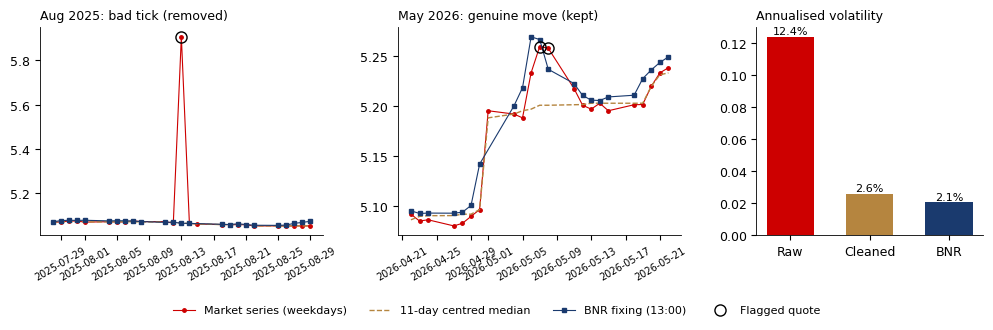

In [ ]:
m = load('EUR/RON (market)', start='2015-01-01'); bnr = load('EUR/RON', start='2015-01-01')
vol = lambda x: np.log(x).diff().dropna().std() * np.sqrt(obs_per_year(x))      # FX: observed frequency, not 252
# 1. weekend rows; 2. 0.05 RON from the 11-day centred median of the weekday quotes
wd = m[m.index.dayofweek < 5]; med = wd.rolling(11, center=True, min_periods=3).median()
flagged = wd.index.difference(clean_series(m, max_dev=0.05).index)
# 3. compare each flag with the BNR fixing of that day (last earlier fixing on a holiday); remove only confirmed errors
gap_bnr = pd.Series({d: abs(wd[d] - bnr.asof(d)) for d in flagged})
confirmed = gap_bnr.index[gap_bnr > 0.05]; rule = wd.drop(confirmed)
audit = pd.DataFrame({'quote': wd[flagged], 'median': med[flagged], 'BNR': [bnr.asof(d) for d in flagged],
                      'BNR fixing date': [bnr.index[bnr.index <= d][-1].date() for d in flagged], 'gap to BNR': gap_bnr,
                      'decision': np.where(gap_bnr > 0.05, 'removed', 'kept')})
audit.index = audit.index.date; print(audit.round(4).to_string())
print(f'rows {len(m)}, weekend rows {int((m.index.dayofweek >= 5).sum())}, weekday quotes flagged {len(flagged)}, errors removed {len(confirmed)}')
# 4. three volatilities, each with its own observed q
for lab, x in [('raw', m), ('cleaned', rule), ('BNR', bnr)]:
    print(f'{lab:8s}: q = {obs_per_year(x):.0f}, annualised volatility {vol(x):.2%}')
# the remaining gap: timing and residual quote noise
j = np.log(pd.concat([rule, bnr], axis=1, keys=['mkt', 'bnr']).dropna()).diff().dropna()   # prices joined on common days first
ac = lambda x: np.log(x).diff().dropna().autocorr(1)                                        # each series on its own calendar
print(f"corr of daily changes {j['mkt'].corr(j['bnr']):.2f} on {len(j)} common days; lag-1 autocorrelation market series {ac(rule):.2f}, "
      f"BNR {ac(bnr):.2f}; days of the market series without a BNR fixing {len(rule.index.difference(bnr.index))}")
fig, axes = plt.subplots(1, 3, figsize=(10, 3), gridspec_kw={'width_ratios': [1, 1, 0.8]})
for ax, (a, b, ttl) in zip(axes[:2], [('2025-07-28', '2025-08-29', 'Aug 2025: bad tick (removed)'),
                                       ('2026-04-22', '2026-05-22', 'May 2026: genuine move (kept)')]):
    ax.plot(wd.loc[a:b].index, wd.loc[a:b], 'o-', color=IDAred, lw=0.8, ms=2.5, label='Market series (weekdays)')
    ax.plot(med.loc[a:b].index, med.loc[a:b], color=Amber, lw=1.0, ls='--', label='11-day centred median')
    ax.plot(bnr.loc[a:b].index, bnr.loc[a:b], 's-', color=MainBlue, lw=0.8, ms=2.2, label='BNR fixing (13:00)')
    for d in flagged:
        if pd.Timestamp(a) <= d <= pd.Timestamp(b):
            ax.plot(d, wd[d], 'o', ms=8, mfc='none', mec='black', label='Flagged quote')
    ax.set_title(ttl, loc='left', fontsize=9); ax.tick_params(axis='x', labelsize=7, rotation=30)
v = [vol(m), vol(rule), vol(bnr)]
axes[2].bar(['Raw', 'Cleaned', 'BNR'], v, color=[IDAred, Amber, MainBlue], width=0.6)
for k, x in enumerate(v):
    axes[2].annotate(f'{x:.1%}', (k, x), xytext=(0, 2), textcoords='offset points', ha='center', fontsize=8)
axes[2].set_title('Annualised volatility', loc='left', fontsize=9)
bottom_legend(fig, ncol=4); plt.show()

**Interpretare (soluție).** Nouă bad ticks multiplică volatilitatea de aproape cinci ori. Diferența care rămîne este compatibilă cu decalajele de moment (cotația de piață nu este preluată la fixing-ul de la ora 13:00) și cu zgomotul rezidual al cotațiilor; datele zilnice nu le pot separa pe cele două. Folosiți cursul oficial BNR: o regulă cu prag elimină erorile grosiere, nu și diferențele rămase. Mediana centrată folosește cotații viitoare, deci aceasta este o curățare retrospectivă, nu un filtru în timp real.

### B2 șase active [Rezolvat]. Un tablou de bord pentru mai multe clase de active <a id="B2f"></a>

**Întrebări.**
- Cît a crescut 1 USD în șase clase de active din 2015?
- Cît de volatilă a fost fiecare?

**Date.** SPY (adjusted close), Euro Stoxx 50 și Nikkei 225 (close, convertite în USD), aur (cotații din zilele lucrătoare), TLT (adjusted close), Bitcoin (close), 2 ian. 2015 – 18 sep. 2026.

**Cerințe.**
1. Convertiți Euro Stoxx 50 și Nikkei 225 în USD: $P^{USD} = P^{EUR} \times$ (USD per EUR), $P^{USD} = P^{JPY}/$(JPY per USD), cu cursul FRED din aceeași zi sau, dacă lipsește, cu ultimul curs disponibil din cel mult 5 zile calendaristice anterioare.
2. Reprezentați grafic creșterea unui USD, $P_t/P_0$, pe scală logaritmică.
3. Pentru fiecare activ calculați $n$, $Y$, $q = n/Y$, multiplul, CAGR și volatilitatea $\hat\sigma_d\sqrt{q}$.
4. Recalculați fiecare volatilitate cu $q = 252$.

**Raportați:** graficul și un tabel ($q$, multiplu, CAGR, volatilitate, volatilitate cu 252). **Interpretare:**
- Pentru care active contează alegerea lui $q$?
- De ce contează pentru ele?

Verificați aurul comparativ cu ETF-ul GLD.

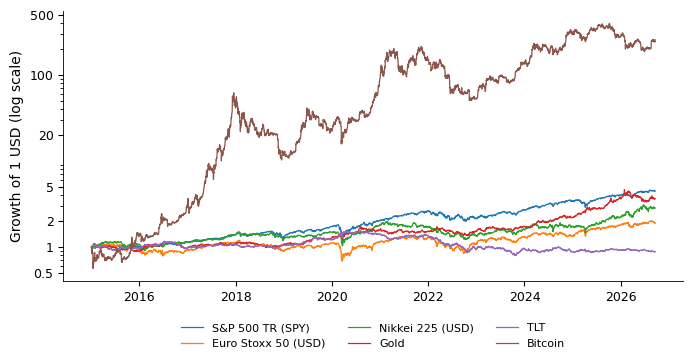

                        n       Y        q  multiple   CAGR    vol  vol with 252
asset                                                                           
S&P 500 TR (SPY)     2944  11.710  251.414     4.500  0.137  0.176         0.176
Euro Stoxx 50 (USD)  3003  11.710  256.452     1.895  0.056  0.207         0.205
Nikkei 225 (USD)     2862  11.702  244.582     2.848  0.094  0.213         0.216
Gold                 3050  11.710  260.466     3.683  0.118  0.163         0.161
TLT                  2944  11.710  251.414     0.884 -0.010  0.147         0.148
Bitcoin              4277  11.710  365.250   256.804  0.606  0.667         0.554


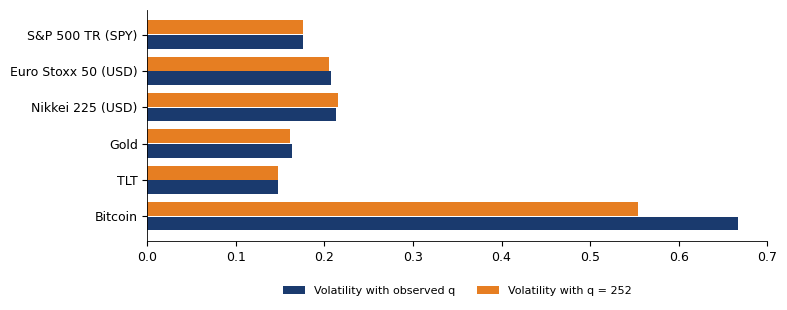

GLD cross-check: vol 0.163 (252 trading days); gold: 0.1633 vs 0.1606


In [ ]:
px = load_panel(['SPY', 'Euro Stoxx 50', 'Nikkei 225', 'Gold', 'US Treasuries 20y+ (TLT)', 'Bitcoin'])
fx_usd = load_panel(['USD per EUR', 'JPY per USD'])
assets = {'S&P 500 TR (SPY)': px['SPY'].dropna(),
          'Euro Stoxx 50 (USD)': to_usd(px['Euro Stoxx 50'].dropna(), fx_usd['USD per EUR']),
          'Nikkei 225 (USD)': to_usd(px['Nikkei 225'].dropna(), fx_usd['JPY per USD'], invert=True),
          'Gold': px['Gold'].dropna(), 'TLT': px['US Treasuries 20y+ (TLT)'].dropna(), 'Bitcoin': px['Bitcoin'].dropna()}
assets = {k: v.loc['2015-01-02':] for k, v in assets.items()}
fig, ax = plt.subplots(figsize=(8, 3.5)); rows = []
for n, p in assets.items():
    ax.plot(p.index, p / p.iloc[0], lw=0.9, label=n)
    q = obs_per_year(p); Y = (p.index[-1] - p.index[0]).days / 365.25; r = np.log(p).diff().dropna()
    rows.append((n, len(r), Y, q, p.iloc[-1] / p.iloc[0], (p.iloc[-1] / p.iloc[0]) ** (1 / Y) - 1, r.std() * np.sqrt(q), r.std() * np.sqrt(252)))
log_axis(ax, [0.5, 1, 2, 5, 20, 100, 500]); ax.set_ylabel('Growth of 1 USD (log scale)')
legend_outside_bottom(ax, ncol=3, y=-0.12); plt.show()
tab = pd.DataFrame(rows, columns=['asset', 'n', 'Y', 'q', 'multiple', 'CAGR', 'vol', 'vol with 252']).set_index('asset')
print(tab.round(3).to_string())
fig, ax = plt.subplots(figsize=(8, 3)); yy = np.arange(len(tab))
ax.barh(yy + 0.2, tab['vol'], 0.38, color=MainBlue, label='Volatility with observed q')
ax.barh(yy - 0.2, tab['vol with 252'], 0.38, color=Orange, label='Volatility with q = 252')
ax.set_yticks(yy); ax.set_yticklabels(tab.index); ax.invert_yaxis(); legend_outside_bottom(ax, ncol=2, y=-0.15); plt.show()
gld = fetch_daily('GLD.US', 'market', 'adjusted_close', start='2015-01-02')
print(f"GLD cross-check: vol {np.log(gld).diff().dropna().std() * np.sqrt(252):.3f} (252 trading days); gold: {tab.loc['Gold', 'vol']:.4f} vs {tab.loc['Gold', 'vol with 252']:.4f}")

**Interpretare (soluție).** $q$ contează pentru Bitcoin (66.7% față de 55.4%, 11 pp), nu și pentru aur (16.3% față de 16.1%, 0.3 pp). Euro Stoxx 50 și Nikkei 225 exclud dividendele: diferența lor față de SPY supraestimează diferența de randament total.

### B6 [Rezolvat]. Corelații și calendare <a id="B6"></a>

**Întrebări.**
- Cît de mult modifică o corelație calendarul și estimatorul?
- S-a schimbat corelația dintre acțiuni și obligațiuni?

**Date.** S&P 500 și Bitcoin (close) și TLT (adjusted close), randamente logaritmice zilnice; Bitcoin – S&P 500 în perioada 1 ian. 2022 – 18 sep. 2026; S&P 500 – TLT în 2010–2020 și 2022–2026.

**Cerințe.**
1. Corelația Bitcoin – S&P 500 pe întreaga perioadă, în zilele comune (prețurile se îmbină mai întîi).
2. Aceeași corelație cu S&P 500 completat prin forward-fill în weekenduri și cu randamente săptămînale: ultimul preț dintr-o zi comună al fiecărei săptămîni care se încheie vinerea (joia, dacă vinerea este zi de sărbătoare); o ultimă săptămînă incompletă se elimină.
3. Media corelației rolling pe 252 de zile în 2022–2026 (ferestrele pot începe în 2021).
4. S&P 500 – TLT în ambele perioade, cu ambii estimatori.
5. Schimbarea corelației acțiuni–obligațiuni: $\hat\rho_1$ (2010–2020, $n_1$ zile), $\hat\rho_2$ (2022–2026, $n_2$ zile), $z_i = \operatorname{atanh}\hat\rho_i$, $SE_z = \sqrt{1/(n_1-3) + 1/(n_2-3)}$ și $z = (z_2 - z_1)/SE_z$ (Fisher, 1915; perechi iid dintr-o distribuție Normală bivariată).
6. Intervalul iid de 95% al diferenței din populație $\rho_2 - \rho_1$: $(\hat\rho_2 - \hat\rho_1) \pm 1.96\sqrt{(1-\hat\rho_1^2)^2/(n_1-3) + (1-\hat\rho_2^2)^2/(n_2-3)}$.

**Raportați:** un grafic al corelațiilor rolling, un tabel metodă / dimensiunea eșantionului / corelație, $z$, $p$-value-ul său și intervalul schimbării. **Interpretare:**
- Ce estimator răspunde la întrebarea „care a fost corelația în 2022–2026”?
- Ce vă permite intervalul schimbării să afirmați?
- Ce nu poate el stabili?

                                 n  correlation
Bitcoin - S&P 500, 2022-2026                   
common days                   1182        0.419
forward-filled                1722        0.392
weekly (Friday)                246        0.299
mean rolling 252              1182        0.378
S&P 500 - TLT 2010-2020: whole period -0.474, mean rolling 252 -0.427, n = 2769
S&P 500 - TLT 2022-2026: whole period 0.109, mean rolling 252 0.082, n = 1182


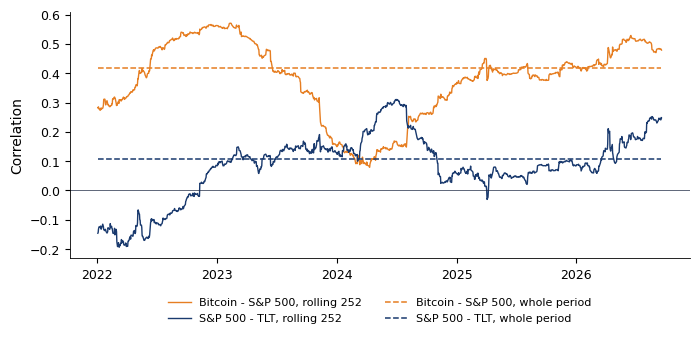

5. rho_1 = -0.4740 (n1 = 2769), rho_2 = 0.1087 (n2 = 1182); z1 = -0.5152, z2 = 0.1091; SE_z = 0.0348; z = 17.9, p = 4.9e-72
6. change +0.583, SE 0.0323, iid 95% interval [0.519, 0.646]


In [ ]:
from scipy import stats
eq, btc, tlt = load('S&P 500'), load('Bitcoin'), load('US Treasuries 20y+ (TLT)')
cb = np.log(pd.concat([eq, btc], axis=1).dropna()).diff().dropna()                          # 1. prices joined first
ffill = np.log(pd.concat([eq.reindex(btc.index).ffill(), btc], axis=1).loc['2021-12-31':]).diff().dropna().loc['2022':]
wp = pd.concat([eq, btc], axis=1).dropna().resample('W-FRI').last()                          # 2. weekly, Friday to Friday
weekly = np.log(wp[wp.index <= cb.index[-1]]).diff().dropna().loc['2022':]
roll_cb = cb.iloc[:, 0].rolling(252).corr(cb.iloc[:, 1])                                     # 3. rolling 252
sb = np.log(pd.concat([eq, tlt], axis=1).dropna()).diff().dropna(); roll_sb = sb.iloc[:, 0].rolling(252).corr(sb.iloc[:, 1])
tab = pd.DataFrame([('common days', len(cb.loc['2022':]), cb.loc['2022':].corr().iloc[0, 1]),
                    ('forward-filled', len(ffill), ffill.corr().iloc[0, 1]),
                    ('weekly (Friday)', len(weekly), weekly.corr().iloc[0, 1]),
                    ('mean rolling 252', len(cb.loc['2022':]), roll_cb.loc['2022':].mean())],
                   columns=['Bitcoin - S&P 500, 2022-2026', 'n', 'correlation']).set_index('Bitcoin - S&P 500, 2022-2026')
print(tab.round(3).to_string())
for a, b in [('2010', '2020'), ('2022', '2026')]:                                             # 4.
    print(f'S&P 500 - TLT {a}-{b}: whole period {sb.loc[a:b].corr().iloc[0, 1]:.3f}, mean rolling 252 {roll_sb.loc[a:b].mean():.3f}, n = {len(sb.loc[a:b])}')
fig, ax = plt.subplots(figsize=(8, 3.2))
rc, rs = roll_cb.loc['2022':], roll_sb.loc['2022':]
ax.plot(rc.index, rc, color=Orange, lw=1.0, label='Bitcoin - S&P 500, rolling 252')
ax.plot(rs.index, rs, color=MainBlue, lw=1.0, label='S&P 500 - TLT, rolling 252')
ax.hlines(tab.iloc[0, 1], rc.index[0], rc.index[-1], color=Orange, ls='--', label='Bitcoin - S&P 500, whole period')
ax.hlines(sb.loc['2022':].corr().iloc[0, 1], rs.index[0], rs.index[-1], color=MainBlue, ls='--', label='S&P 500 - TLT, whole period')
ax.axhline(0, color=Gray, lw=0.5); ax.set_ylabel('Correlation'); legend_outside_bottom(ax, ncol=2, y=-0.12); plt.show()
# 5.-6. the stock-bond change
a_, c_ = sb.loc['2010':'2020'].values, sb.loc['2022':].values; n1, n2 = len(a_), len(c_)
r1, r2 = np.corrcoef(a_.T)[0, 1], np.corrcoef(c_.T)[0, 1]
se_z = np.sqrt(1 / (n1 - 3) + 1 / (n2 - 3)); z = (np.arctanh(r2) - np.arctanh(r1)) / se_z
se_iid = np.sqrt((1 - r1 ** 2) ** 2 / (n1 - 3) + (1 - r2 ** 2) ** 2 / (n2 - 3))
print(f'5. rho_1 = {r1:.4f} (n1 = {n1}), rho_2 = {r2:.4f} (n2 = {n2}); z1 = {np.arctanh(r1):.4f}, z2 = {np.arctanh(r2):.4f}; '
      f'SE_z = {se_z:.4f}; z = {z:.1f}, p = {2 * stats.norm.sf(abs(z)):.1e}')
print(f'6. change {r2 - r1:+.3f}, SE {se_iid:.4f}, iid 95% interval [{r2 - r1 - 1.96 * se_iid:.3f}, {r2 - r1 + 1.96 * se_iid:.3f}]')

**Interpretare (soluție).** Corelația pe întreaga perioadă răspunde la întrebare; media corelațiilor rolling face media unor ferestre de un an (unele începînd în 2021), deci estimează altceva (un alt estimand); calendarul, singur, mută estimarea pentru Bitcoin între 0.30 și 0.42. Schimbarea corelației acțiuni–obligațiuni (+0.58, intervalul [0.52, 0.65]) este mult mai mare decît eroarea de eșantionare iid, dar intervalul nu îi poate stabili cauza, iar ipoteza iid pe care se bazează ignoră volatility clustering (B6 extins).

## Pachetul 2: Precizie <a id="pack2"></a>

A7, B2 extins [Rezolvat]. Cerințe preliminare: Pachetul 1, cursul din Capitolul 0.

### A7 [Rezolvat]. Cît de precis este un randament mediu? <a id="A7"></a>

**Întrebare.** SPY a avut un randament mediu de aproximativ 14% pe an în 2015–2026; cu ce precizie determină acest eșantion media randamentului anual?

**Date.** SPY (adjusted close), randamente zilnice simple $R_t$, 2 ian. 2015 – 18 sep. 2026; $q$ și $Y$ ca în B2 șase active.

**Cerințe.**
1. Calculați media anualizată $\hat\mu_a = q\bar R$ și volatilitatea anualizată $\hat\sigma_a = s_R\sqrt{q}$.
2. Pentru randamente iid, $SE(\hat\mu_a) = q s_R/\sqrt{n} = \hat\sigma_a/\sqrt{Y}$ (deoarece $n = qY$): calculați-l, precum și intervalul de 95% $\hat\mu_a \pm 1.96\,SE$.
3. Cîți ani de date ar fi necesari pentru un interval de 95% de ±2 pp, la aceeași volatilitate?

**Raportați:** $\hat\mu_a$, $\hat\sigma_a$, SE, intervalul și numărul de ani. **Interpretare:** de ce eșantionarea zilnică în locul celei lunare nu face media mai precisă?

In [ ]:
spy = load('SPY', start='2015-01-02'); R = spy.pct_change().dropna()
q = obs_per_year(spy); Y = (spy.index[-1] - spy.index[0]).days / 365.25
mu_a, sig_a = q * R.mean(), R.std(ddof=1) * np.sqrt(q); se = sig_a / np.sqrt(Y)
print(f'1. n = {len(R)}, q = {q:.1f}, Y = {Y:.2f}; mean R = {R.mean():.4%}, s_R = {R.std(ddof=1):.3%}: mu_a = {mu_a:.1%}, sigma_a = {sig_a:.1%}')
print(f'2. SE = {sig_a:.3f} / sqrt({Y:.2f}) = {se:.4f}; 95% interval [{mu_a - 1.96 * se:.1%}, {mu_a + 1.96 * se:.1%}]')
print(f'3. years for +/- 2 pp: (1.96 x {sig_a:.3f} / 0.02)^2 = {(1.96 * sig_a / 0.02) ** 2:.0f}')

1. n = 2944, q = 251.4, Y = 11.71; mean R = 0.0572%, s_R = 1.105%: mu_a = 14.4%, sigma_a = 17.5%
2. SE = 0.175 / sqrt(11.71) = 0.0512; 95% interval [4.3%, 24.4%]
3. years for +/- 2 pp: (1.96 x 0.175 / 0.02)^2 = 295


**Interpretare (soluție).** SE depinde de lungimea perioadei $Y$, nu de numărul de observații: o eșantionare mai frecventă adaugă observații, dar nu și informație despre medie. Aceeași logică determină precizia Sharpe ratio (B2 extins).

### B2 extins [Rezolvat]. Cît de precis este un Sharpe ratio? <a id="B2x"></a>

**Întrebare.** Este Sharpe ratio-ul SPY suficient de precis pentru a-l clasa deasupra aurului?

**Date.** Cele șase serii din B2 șase active, randamente zilnice simple $R_t$, rata fără risc 0.

**Cerințe.**
1. Calculați $SR_a = \sqrt{q}\,\bar R/s_R$ pentru SPY și valoarea zilnică $SR_d = \bar R/s_R$.
2. Calculați standard error-ul asimptotic iid pentru randamente care urmează distribuția Normală (Lo, 2002): $SE = \sqrt{q(1 + SR_d^2/2)/T}$, precum și intervalul de 95% $SR_a \pm 1.96\,SE$.
3. Bootstrap staționar (Politis și Romano, 1994; lungimea medie a blocului 20, 2,000 de reeșantionări, `default_rng(42)`): intervalul percentil de 95% al SR pentru SPY; repetați pentru celelalte cinci active.
4. În zilele comune ale SPY și aurului, aplicați bootstrap diferenței pereche dintre Sharpe ratio-urile lor (ambele cu $q = 252$) și raportați intervalul ei de 95%.

**Raportați:** calculul pentru SPY, un grafic al intervalelor, diferența împreună cu intervalul ei. **Interpretare:** clasează tabelul din B2 șase active SPY deasupra aurului?

                        T        q   SR_a   SR_d  SE Lo  SE Opdyke  SR boot lo  SR boot hi  CAGR boot lo  CAGR boot hi
asset                                                                                                                 
S&P 500 TR (SPY)     2944  251.414  0.821  0.052  0.292      0.296       0.327       1.401         0.044         0.234
Euro Stoxx 50 (USD)  3003  256.452  0.368  0.023  0.292      0.294      -0.168       0.922        -0.056         0.177
Nikkei 225 (USD)     2862  244.582  0.527  0.034  0.292      0.292       0.077       0.989        -0.007         0.200
Gold                 3050  260.466  0.765  0.047  0.292      0.295       0.243       1.335         0.026         0.224
TLT                  2944  251.414  0.002  0.000  0.292      0.292      -0.528       0.512        -0.085         0.066
Bitcoin              4277  365.250  1.050  0.055  0.292      0.294       0.439       1.660         0.067         1.399
SPY step by step: SR_d = 0.82/sqrt(251.4) = 0.05

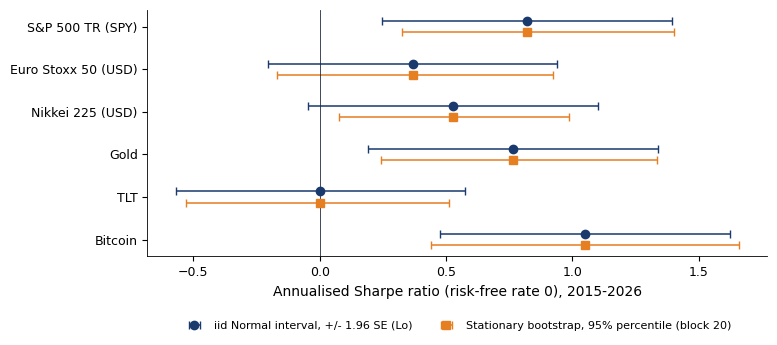

SPY - gold (2944 common days): +0.06, 95% percentile interval [-0.65, +0.88]; share of positive differences 60%; p = 0.81


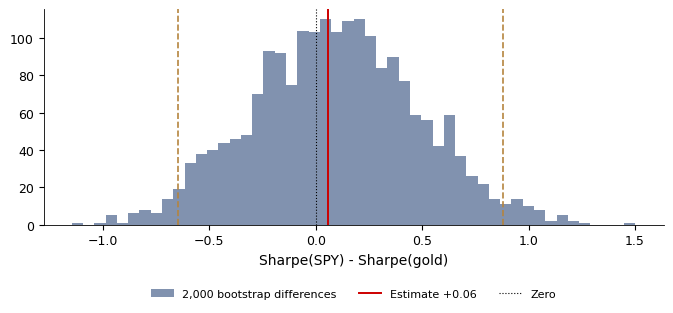

In [ ]:
rng = np.random.default_rng(42)
rows, draws = [], {}
for n, p in assets.items():
    q = obs_per_year(p); years = (p.index[-1] - p.index[0]).days / 365.25
    r = np.log(p).diff().dropna().values; R = np.expm1(r); sr = sharpe(R, q)
    cs, ss = [], []
    for _ in range(2000):
        i = sb_index(len(r), 20, rng); cs.append(np.exp(r[i].sum() / years) - 1); ss.append(sharpe(R[i], q))
    lo, hi = np.percentile(ss, [2.5, 97.5]); draws[n] = (lo, hi)
    rows.append((n, len(R), q, sr, R.mean() / R.std(ddof=1), se_lo(R, q), se_opdyke(R, q), lo, hi, *np.percentile(cs, [2.5, 97.5])))
tab = pd.DataFrame(rows, columns=['asset', 'T', 'q', 'SR_a', 'SR_d', 'SE Lo', 'SE Opdyke', 'SR boot lo', 'SR boot hi',
                                  'CAGR boot lo', 'CAGR boot hi']).set_index('asset')
print(tab.round(3).to_string())
s = tab.loc['S&P 500 TR (SPY)']
print(f"SPY step by step: SR_d = {s['SR_a']:.2f}/sqrt({s['q']:.1f}) = {s['SR_d']:.3f}; SE = sqrt({s['q']:.1f} x (1 + {s['SR_d']:.3f}^2/2)/{int(s['T'])}) = {s['SE Lo']:.3f}; "
      f"iid 95% [{s['SR_a'] - 1.96 * s['SE Lo']:.2f}, {s['SR_a'] + 1.96 * s['SE Lo']:.2f}]; bootstrap [{s['SR boot lo']:.2f}, {s['SR boot hi']:.2f}]")
fig, ax = plt.subplots(figsize=(8, 3.2)); yy = np.arange(len(tab))
ax.errorbar(tab['SR_a'], yy - 0.13, xerr=1.96 * tab['SE Lo'], fmt='o', color=MainBlue, capsize=3, label='iid Normal interval, +/- 1.96 SE (Lo)')
ax.errorbar(tab['SR_a'], yy + 0.13, xerr=[tab['SR_a'] - tab['SR boot lo'], tab['SR boot hi'] - tab['SR_a']], fmt='s', color=Orange,
            capsize=3, label='Stationary bootstrap, 95% percentile (block 20)')
ax.axvline(0, color=Gray, lw=0.6); ax.set_yticks(yy); ax.set_yticklabels(tab.index); ax.invert_yaxis()
ax.set_xlabel('Annualised Sharpe ratio (risk-free rate 0), 2015-2026'); legend_outside_bottom(ax, ncol=2, y=-0.22); plt.show()
# 4. SPY minus gold on common days, paired bootstrap (both with q = 252)
j = np.log(pd.concat([assets['S&P 500 TR (SPY)'], assets['Gold']], axis=1).dropna()).diff().dropna(); Rj = np.expm1(j.values)
d0 = sharpe(Rj[:, 0], 252) - sharpe(Rj[:, 1], 252)
ds = np.array([sharpe(Rj[i, 0], 252) - sharpe(Rj[i, 1], 252) for i in (sb_index(len(Rj), 20, rng) for _ in range(2000))])
lo, hi = np.percentile(ds, [2.5, 97.5])
print(f'SPY - gold ({len(Rj)} common days): {d0:+.2f}, 95% percentile interval [{lo:+.2f}, {hi:+.2f}]; '
      f'share of positive differences {(ds > 0).mean():.0%}; p = {min(1, 2 * min((ds <= 0).mean(), (ds >= 0).mean())):.2f}')
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.hist(ds, bins=50, color=MainBlue, alpha=0.55, label='2,000 bootstrap differences')
ax.axvline(d0, color=IDAred, lw=1.4, label=f'Estimate {d0:+.2f}')
for v in (lo, hi):
    ax.axvline(v, color=Amber, ls='--', lw=1.2)
ax.axvline(0, color='black', ls=':', lw=0.8, label='Zero'); ax.set_xlabel('Sharpe(SPY) - Sharpe(gold)')
legend_outside_bottom(ax, ncol=3, y=-0.25); plt.show()

**Interpretare (soluție).** Fiecare SE iid este aproximativ $1/\sqrt{11.71} = 0.29$: cu date zilnice, SE aproape că nu depinde de activ. Diferența SPY–aur (+0.06) are un interval care conține 0: 11.7 ani nu sînt suficienți pentru a clasa SPY deasupra aurului; tabelul din B2 descrie eșantionul.

**Verificare opțională: sensibilitatea la lungimea medie a blocului** (blocuri de 5 și de 60 de zile, cîte 1,000 de reeșantionări fiecare, generator propriu `default_rng(42)`).

In [ ]:
rng_b = np.random.default_rng(42); sens = []
for n, p in assets.items():
    q = obs_per_year(p); r = np.log(p).diff().dropna().values; R = np.expm1(r); row = [n]
    for mb in (5, 60):
        ss = [sharpe(R[i], q) for i in (sb_index(len(r), mb, rng_b) for _ in range(1000))]
        row.append(f'[{np.percentile(ss, 2.5):.2f}, {np.percentile(ss, 97.5):.2f}]')
    sens.append(row)
print(pd.DataFrame(sens, columns=['asset', 'SR 95% block 5', 'SR 95% block 60']).set_index('asset').to_string())

                    SR 95% block 5 SR 95% block 60
asset                                             
S&P 500 TR (SPY)      [0.29, 1.39]    [0.39, 1.34]
Euro Stoxx 50 (USD)  [-0.21, 0.98]   [-0.14, 0.91]
Nikkei 225 (USD)      [0.04, 1.04]    [0.11, 0.98]
Gold                  [0.19, 1.36]    [0.22, 1.31]
TLT                  [-0.52, 0.53]   [-0.52, 0.54]
Bitcoin               [0.51, 1.66]    [0.44, 1.72]


**Extensie opțională: toate perechile celor cinci active non-crypto** (bootstrap comun al fiecărei diferențe de Sharpe ratio în zilele comune, generator `default_rng(2026)`; Bonferroni: 10 teste, fiecare la 0.5%).

In [ ]:
import itertools
rng_pairs = np.random.default_rng(2026)
for a, b in itertools.combinations([k for k in assets if k != 'Bitcoin'], 2):
    jj = np.log(pd.concat([assets[a], assets[b]], axis=1).dropna()).diff().dropna(); Rp = np.expm1(jj.values)
    dd = np.array([sharpe(Rp[i, 0], 252) - sharpe(Rp[i, 1], 252) for i in (sb_index(len(Rp), 20, rng_pairs) for _ in range(2000))])
    p = min(1, 2 * min((dd <= 0).mean(), (dd >= 0).mean()))
    print(f'{a} - {b}: {sharpe(Rp[:, 0], 252) - sharpe(Rp[:, 1], 252):+.2f}, 95% CI [{np.percentile(dd, 2.5):+.2f}, {np.percentile(dd, 97.5):+.2f}], '
          f'99.5% CI [{np.percentile(dd, 0.25):+.2f}, {np.percentile(dd, 99.75):+.2f}], bootstrap p = {p:.3f}')

S&P 500 TR (SPY) - Euro Stoxx 50 (USD): +0.46, 95% CI [+0.09, +0.85], 99.5% CI [-0.06, +1.03], bootstrap p = 0.012


S&P 500 TR (SPY) - Nikkei 225 (USD): +0.32, 95% CI [-0.04, +0.75], 99.5% CI [-0.18, +0.95], bootstrap p = 0.097


S&P 500 TR (SPY) - Gold: +0.06, 95% CI [-0.63, +0.82], 99.5% CI [-0.91, +1.11], bootstrap p = 0.824


S&P 500 TR (SPY) - TLT: +0.82, 95% CI [+0.05, +1.62], 99.5% CI [-0.32, +1.97], bootstrap p = 0.036


Euro Stoxx 50 (USD) - Nikkei 225 (USD): -0.14, 95% CI [-0.52, +0.23], 99.5% CI [-0.67, +0.44], bootstrap p = 0.467


Euro Stoxx 50 (USD) - Gold: -0.39, 95% CI [-1.04, +0.30], 99.5% CI [-1.25, +0.55], bootstrap p = 0.257


Euro Stoxx 50 (USD) - TLT: +0.37, 95% CI [-0.38, +1.13], 99.5% CI [-0.72, +1.42], bootstrap p = 0.321


Nikkei 225 (USD) - Gold: -0.24, 95% CI [-0.91, +0.51], 99.5% CI [-1.20, +0.77], bootstrap p = 0.505


Nikkei 225 (USD) - TLT: +0.55, 95% CI [-0.12, +1.24], 99.5% CI [-0.42, +1.60], bootstrap p = 0.109


Gold - TLT: +0.76, 95% CI [+0.17, +1.34], 99.5% CI [-0.09, +1.63], bootstrap p = 0.008


## Pachetul 3: Aritmetica randamentelor <a id="pack3"></a>

A8 [Rezolvat], A9, A10. Cerințe preliminare: Pachetul 2.

### A8 [Rezolvat]. Volatility drag <a id="A8"></a>

**Întrebare.** Poate un randament mediu pozitiv să coexiste cu o avere în scădere? **Notații** (zilnice): $m = E[r]$, $a = E[R]$, $v_R = \operatorname{Var}(R)$, $v_r = \operatorname{Var}(r)$, $r = \ln(1 + R)$.

**Date.** Bitcoin, prețul zilnic de închidere în USD, de la 17 sep. 2014 (457.33) pînă la 18 sep. 2026 (80,901.46), 4,384 de randamente zilnice, 365 pe an.

**Cerințe.**
1. Dezvoltați $\ln(1+R)$ pînă la ordinul doi și arătați că $m \approx a - (v_R + a^2)/2 \approx a - v_r/2$ pentru randamente zilnice mici.
2. Pentru Bitcoin, completați un tabel de trecere de la valori zilnice la valori anuale: media logaritmică ×365, drag-ul $v_r \times 365/2$, media simplă implicită, CAGR $= e^{365m} - 1$; comparați cu CAGR calculat din prețurile de la cele două capete ale perioadei.
3. Un activ are o medie aritmetică anuală de 10% și o volatilitate de 60%: aproximați media creșterii sale logaritmice și CAGR.

**Interpretare.** De ce poate traiectoria tipică să piardă bani atunci cînd randamentul mediu este pozitiv?

In [ ]:
btc = load('Bitcoin', start='2014-09-17')
r = np.log(btc).diff().dropna(); R = np.expm1(r)
m_d, s_d = r.mean(), r.std()
mu_log = m_d * 365; half_var = s_d ** 2 * 365 / 2
years = (btc.index[-1] - btc.index[0]).days / 365.25
print(f'2. daily log mean {m_d:.4%}, daily sd {s_d:.3%}; log mean x 365 {mu_log:.1%}, drag {half_var:.3f}')
print(f'   implied simple mean {mu_log + half_var:.1%} (direct: 365 x mean of R_t = {R.mean() * 365:.1%}); CAGR = e^(365 m) - 1 = {np.exp(mu_log) - 1:.1%} '
      f'(from {btc.iloc[0]:.2f} to {btc.iloc[-1]:.2f}: {(btc.iloc[-1] / btc.iloc[0]) ** (1 / years) - 1:.1%})')
print(f'3. log growth 0.10 - 0.60^2/2 = {0.10 - 0.6 ** 2 / 2:.3f}, CAGR {np.exp(0.10 - 0.18) - 1:.1%}; '
      f'exact if annual log returns are Normal: ln 1.10 - 0.18 = {np.log(1.1) - 0.18:.3f}, CAGR {np.exp(np.log(1.1) - 0.18) - 1:.1%}')

2. daily log mean 0.1181%, daily sd 3.485%; log mean x 365 43.1%, drag 0.222
   implied simple mean 65.3% (direct: 365 x mean of R_t = 65.2%); CAGR = e^(365 m) - 1 = 53.9% (from 457.33 to 80901.46: 53.9%)
3. log growth 0.10 - 0.60^2/2 = -0.080, CAGR -7.7%; exact if annual log returns are Normal: ln 1.10 - 0.18 = -0.085, CAGR -8.1%


### A9 [Propus]. Cînd eșuează regula $\sqrt{q}$ <a id="A9"></a>

**Model:** A2–A3 și A8 [Rezolvat]. **Teorie** (randamente logaritmice zilnice, staționare, cu varianța $\sigma^2$ și autocorelațiile $\rho_j$):
1. Pentru $k = 3$, scrieți $\operatorname{Var}(r_1 + r_2 + r_3)$ ca sumă a celor nouă covarianțe; apoi generalizați la $\operatorname{Var}(\sum_{t=1}^{k} r_t) = k\sigma^2[1 + 2\sum_{j=1}^{k-1}(1 - j/k)\rho_j]$.
2. Pentru un proces AR(1) *ipotetic*, $\rho_j = \rho^j$, găsiți limita parantezei cînd $k \to \infty$.

**Date:** BNR EUR/RON, 4 iul. 2005 – 18 sep. 2026, 5,352 de variații logaritmice zilnice.

3. Calculați $\hat\rho_1$, volatilitatea cu $\sqrt{252}$ și corecția ei ipotetică AR(1).
4. Calculați autocorelațiile la lagurile 1–10 și volatilitatea din variațiile de la sfîrșit de lună ×$\sqrt{12}$.
5. Seria EUR/RON de la EODHD (B1) are $\hat\rho_1 = -0.57$:
   - care ar fi factorul AR(1)?
   - de ce este o corecție greșită?

**Interpretare.**
- Autocorelația pozitivă ascunde risc sau inventează risc?
- Este $\hat\rho_1$ suficient?

In [ ]:
# Your code here

### A10 [Propus]. Standard error-ul unui Sharpe ratio <a id="A10"></a>

**Model:** A8, A7 și B2 extins [Rezolvat]. **Cadru:** $T$ randamente zilnice iid cu media $\mu$, varianța $\sigma^2$, momentele centrale $\mu_3, \mu_4$ (finite), skewness $\gamma_3 = \mu_3/\sigma^3$, kurtosis obișnuită (nu în exces) $\gamma_4 = \mu_4/\sigma^4$; $SR = \mu/\sigma$ zilnic. **Date:** SPY (B2 extins): $SR_a = 0.82$, $q = 251.4$, $T = 2944$, $Y = 11.71$, $\gamma_3 = -0.31$, $\gamma_4 = 17.1$.

1. Gradientul: pentru $g(\mu, \sigma^2) = \mu/\sigma$, calculați $\nabla g$.
2. Forma pătratică: $\sqrt{T}(\hat\mu - \mu, \hat\sigma^2 - \sigma^2) \to N(0, \Sigma)$, $\Sigma = [[\sigma^2, \mu_3], [\mu_3, \mu_4 - \sigma^4]]$; calculați $\nabla g^\top \Sigma \nabla g$ și cazul ei Normal (Lo, 2002).
3. Scalarea anuală, cazul Normal: cu $SR_a = \sqrt{q}\,SR_d$ și $T = qY$, arătați că varianța asimptotică este $\operatorname{Var}(\widehat{SR}_a) \approx (1 + SR_a^2/(2q))/Y$ (o aproximare pentru $T$ mare, nu un rezultat exact pentru eșantion finit).
4. Calculați SE asimptotic al SPY în trei moduri: Normal zilnic, general zilnic (cu $\gamma_3$, $\gamma_4$) și aceeași formulă Normală cu $q = 1$, $\sqrt{(1 + SR_a^2/2)/Y}$, ca și cum perioada ar fi observată prin randamente anuale; precizați ipoteza de eșantionare a fiecăruia.

**Interpretare.** De ce eșantionarea mai frecventă decît lunară ajută foarte puțin?

In [ ]:
# Your code here

## Pachetul 4: Inferență pentru corelații <a id="pack4"></a>

B6 extins, A11, A12, C2. Cerințe preliminare: Pachetele 1–2.

### B6 extins [Propus]. Rezistă schimbarea corelației acțiuni–obligațiuni la dependență? <a id="B6x"></a>

**Model:** B6 (intervalul iid al unei schimbări de corelație) și B2 extins (bootstrap staționar) [Rezolvat]. **Date:** B6, randamentele logaritmice zilnice S&P 500 – TLT în zilele comune: 2010–2020 ($n_1 = 2769$) și 2022 – 18 sep. 2026 ($n_2 = 1182$).

1. Aplicați bootstrap staționar fiecărei perioade separat (bloc 20, 2,000 de reeșantionări, `default_rng(42)`): recalculați $\hat\rho_2^* - \hat\rho_1^*$ pe fiecare pereche de reeșantionări.
2. Raportați intervalul percentil de 95% al lui $\rho_2 - \rho_1$ și reprezentați histograma schimbărilor bootstrap împreună cu ambele intervale.
3. Comparați lățimea lui cu lățimea intervalului iid din B6 (cerința 6).
4. Pentru A11 (e): Bitcoin – S&P 500 (2022–2026), intervalele Fisher și bootstrap pentru corelația zilnică și pentru cea săptămînală, precum și un bootstrap comun al diferenței lor (săptămîni reeșantionate în blocuri de lungime medie 4, generator `default_rng(2026)`, ambele corelații fiind recalculate din fiecare reeșantionare).

**Interpretare.**
- De ce este intervalul bootstrap mai larg?
- Rezistă concluzia din B6?

In [ ]:
# Your code here

### A11 [Propus]. De ce este corelația săptămînală mai mică? <a id="A11"></a>

**Model:** B6 [Rezolvat]. **Date:** $x_t$ = S&P 500, $y_t$ = Bitcoin, randamente logaritmice zilnice în zilele comune, 2022 – 18 sep. 2026, $n = 1182$; $\gamma(j) = \operatorname{Cov}(x_t, y_{t-j})$.

1. Pentru sumele $X, Y$ a cîte 5 randamente consecutive din zile comune, desenați grila $5 \times 5$ a covarianțelor și arătați că $\operatorname{Cov}(X,Y) = 5\gamma(0) + \sum_{j=1}^{4}(5-j)[\gamma(j) + \gamma(-j)]$ și $\operatorname{Var}(X) = 5\sigma_x^2 f_x$, $f_x = 1 + 2\sum_{j=1}^{4}(1 - j/5)\rho_{x,j}$; prin urmare $\rho_5 = \{\rho_1 + \sum_{j=1}^{4}(5-j)[\gamma(j)+\gamma(-j)]/(5\sigma_x\sigma_y)\}/\sqrt{f_x f_y}$.
2. Verificați simplificarea care presupune absența autocorelației proprii ($f_x = f_y = 1$): autocorelațiile proprii ale lui $x$ și $y$ la lagurile 1–4, precum și $f_x$, $f_y$.
3. Calculați termenul de lag, $\rho_5$ implicit cu și fără $\sqrt{f_x f_y}$, precum și corelația sumelor suprapuse pe 5 zile.
4. Calculați corelația săptămînală pentru săptămîni ancorate în ziua de luni, …, vineri, fiecare cu un interval Fisher de 95%.
5. Raportați intervalul bootstrap comun, pe blocuri de săptămîni, al diferenței zilnic minus săptămînal ([B6 extins](#B6x), punctul 4).

**Interpretare.** Este diferența 0.42 față de 0.30 o proprietate a piețelor sau a eșantionării? Efectul Epps (1979) prezice semnul opus.

In [ ]:
# Your code here

### A12 [Propus]. Închideri asincrone <a id="A12"></a>

**Model:** B6 [Rezolvat]. **Cadru:** log-prețurile $X(s) = W(s) + U(s)$ (Bitcoin) și $Y(s) = W(s) + V(s)$ (S&P 500), cu $W, U, V$ mișcări browniene independente, avînd ratele de varianță $\sigma_W^2, \sigma_U^2, \sigma_V^2$; $\rho = \sigma_W^2/\sqrt{(\sigma_W^2 + \sigma_U^2)(\sigma_W^2 + \sigma_V^2)}$. $X$ se închide la momentele întregi $t$ (24:00 UTC); $Y$ se închide cu o fracțiune $\delta$ dintr-o zi mai devreme (20:00 UTC vara, 21:00 iarna).

1. Desenați pe o axă a timpului intervalele acoperite de $x_t$, $y_t$ și $y_{t+1}$ și arătați că $\operatorname{Corr}(x_t, y_t) = \rho(1-\delta)$, $\operatorname{Corr}(x_t, y_{t+1}) = \rho\delta$, iar toate celelalte corelații încrucișate sînt 0.
2. Deduceți că suma corelațiilor la lagurile −1, 0, +1 este $\rho$ (Scholes și Williams, 1977).
3. Calculați $\delta$ vara și iarna, precum și corelațiile implicite pentru $\rho = 0.45$.
4. Tabelați valorile observate $\operatorname{Corr}(x_t, y_{t+j})$, $j = -1, 0, 1$, pentru 2022–2026 și comparați.

**Interpretare.** Este importantă pentru această pereche distorsiunea cauzată de închiderile asincrone? Tratați suma ca pe un diagnostic.

In [ ]:
# Your code here

### C2 [Propus]. Au schimbat ETF-urile spot corelația dintre Bitcoin și acțiuni? <a id="C2"></a>

**Model:** B6 [Rezolvat] (o schimbare de corelație cu intervalul ei) și B2 extins [Rezolvat] (bootstrap staționar al unei diferențe pereche).

**Întrebare.** ETF-urile spot pe Bitcoin din SUA au început să se tranzacționeze la 11 ian. 2024 (aprobarea a venit la 10 ian. 2024; data începerii tranzacționării este punctul de ruptură folosit aici); s-a schimbat corelația Bitcoin – S&P 500 la acea dată?

**Date.** Bitcoin și S&P 500, randamente logaritmice zilnice în zilele comune, 2018 – 18 sep. 2026.

**Analiza de bază obligatorie.**
1. Corelațiile în 2018–2019, 2020–2021, 1 ian. 2022 – 10 ian. 2024 (pre) și 11 ian. 2024 – 18 sep. 2026 (post), fiecare cu un interval de 95% obținut prin bootstrap staționar (bloc 20, `default_rng(42)`).
2. Testați $H_0: \rho_{post} - \rho_{pre} = 0$ cu un interval bootstrap al diferenței; reprezentați grafic corelația rolling, marcînd data ETF.

**Extensii de proiect** (opționale): un activ contrafactual fără eveniment ETF (precizați de ce este comparabil), o căutare a rupturii cu dată cunoscută (Chow, 1960) comparativ cu dată necunoscută (Andrews, 1993), alte calendare, ferestre și blocuri bootstrap.

**Raportați:** un tabel perioadă / $n$ / $\hat\rho$ / interval, diferența, o figură, o limitare; o afirmație cauzală necesită extensiile.

In [ ]:
# Your code here

## Pachetul 5: Drawdown-uri extreme <a id="pack5"></a>

B5 extins. Cerințe preliminare: B5, Pachetul 2.

### B5 extins [Propus]. Este extrem drawdown-ul din 2009? <a id="B5x"></a>

**Model:** B2 extins [Rezolvat] și B5. **Date:** randamentele logaritmice zilnice $r_t$ ale S&P 500, 3 ian. 2000 – 18 sep. 2026, $n = 6717$; MDD-ul observat și cel mai lung episod obținute de voi în B5, în zile de tranzacționare (episoadele încă deschise la final sînt cenzurate în ultima zi).

1. Construiți o traiectorie: reeșantionați $n$ randamente, setați $\ln P_t = \ln P_0 + \sum_{s \le t} r^*_s$, calculați MDD-ul și cel mai lung episod al ei; reprezentați-o grafic.
2. Repetați de 5,000 de ori cu bootstrap iid și de 5,000 de ori cu bootstrap staționar (bloc 20); seed 42.
3. Reprezentați grafic ambele distribuții ale MDD și ale celui mai lung episod și marcați valorile observate; raportați medianele, cuantilele din coada nefavorabilă (5% pentru MDD, 95% pentru episod) și proporțiile din coadă $P(MDD^* \le MDD_{obs})$ și $P(\text{spell}^* \ge \text{spell}_{obs})$.
4. Calculați $\hat\rho_1$ și $\widehat{VR}(20) = \widehat{\operatorname{Var}}(r_t + \dots + r_{t-19})/(20\,\widehat{\operatorname{Var}}(r_t))$ din toate sumele suprapuse pe 20 de zile, cu varianțe de eșantion calculate cu divizorul (numărul de termeni − 1), fără corecție pentru eșantion mic.

**Interpretare.** Este MDD-ul observat extrem pentru această distribuție a randamentelor? Randamentele reeșantionate includ chiar criza, deci acesta este un diagnostic, nu o prognoză.

In [ ]:
# Your code here

## Pachetul 6: Piața românească <a id="pack6"></a>

B7 [Rezolvat], B8, B9, B9 extins, B1 extins. Cerințe preliminare: Pachetul 1, regresia OLS.

### B7 [Rezolvat]. Event study: taxa bancară din decembrie 2018 <a id="B7"></a>

**Întrebare.** Cît a pierdut Banca Transilvania la vestea taxei bancare, dincolo de mișcarea pieței? **Eveniment:** taxa a fost anunțată în seara zilei de 18 dec. 2018; ziua evenimentului 0 = 19 dec. 2018; indicele zilei de tranzacționare $\tau$.

**Date.** Banca Transilvania (TLV, adjusted close) și indicele BET (close), randamente logaritmice zilnice; fereastra de estimare $[-250, -11]$ (18 dec. 2017 – 4 dec. 2018, $T = 240$); fereastra evenimentului $[0, +5]$ ($L = 6$).

**Metodă.** MacKinlay (1997); Campbell, Lo și MacKinlay (1997), Cap. 4. Erori iid Normale cu varianța $\sigma_\varepsilon^2$, independente de randamentul pieței, cu aceeași varianță în fereastra de estimare și în fereastra evenimentului, iar erorile din fereastra evenimentului sînt independente de erorile din fereastra de estimare.

**Cerințe.**
1. Estimați $r_{i,t} = a + b\,r_{m,t} + \varepsilon_t$ prin OLS: raportați $\hat a$, $\hat b$, $\hat\sigma_\varepsilon$, $\bar r_m$ și $S_{mm} = \sum(r_{m,t} - \bar r_m)^2$.
2. Randamentul anormal $AR_\tau = r_{i,\tau} - (\hat a + \hat b\,r_{m,\tau})$; completați un tabel zi / $r_i$ / $r_m$ / valoarea prezisă $\hat a + \hat b r_m$ / $AR$; $CAR[0,+5] = \sum_{\tau=0}^{5} AR_\tau$.
3. Testați $AR_0 = 0$ și $CAR = 0$ folosind varianțele erorii de predicție $\hat\sigma_\varepsilon^2[1 + 1/T + (r_{m,0} - \bar r_m)^2/S_{mm}]$ și $\hat\sigma_\varepsilon^2[L + L^2/T + (\sum_\tau r_{m,\tau} - L\bar r_m)^2/S_{mm}]$; în ipotezele de mai sus, rapoartele urmează distribuția Student $t$ cu $T - 2$ grade de libertate; altfel, $p$-value-urile sînt aproximări.

**Interpretare.**
- BET conține ambele bănci mari: ce efect are acest lucru asupra lui $\hat b$ și asupra AR?
- A existat o inversare în zilele următoare?
- Ce spune aceasta despre eficiența pieței ([Capitolul 2](https://danpele.github.io/MFM/EN/Courses/chapter2_market_efficiency.pdf))?

Amintiți-vă că $r_i$, $r_m$ și $AR$ sînt randamente logaritmice.

Banca Transilvania: estimation window 2017-12-18 - 2018-12-04 (T = 240); a = 0.0655% a day, b = 1.176, sigma_e = 0.832%, mean r_m = 0.060%, S_mm = 0.01285
                  r_i    r_m  predicted    AR
0 (2018-12-19) -22.21 -11.89     -13.91 -8.29
1 (2018-12-20)   0.95  -1.92      -2.20  3.15
2 (2018-12-21)  -5.41  -5.19      -6.04  0.63
3 (2018-12-24)  10.54   6.82       8.08  2.46
4 (2018-12-27)   0.00  -0.13      -0.08  0.08
5 (2018-12-28)   0.50  -0.37      -0.37  0.87 
CAR[0,+5] = -1.10%
AR_0: leverage (r_m0 - mean)^2/S_mm = 1.112, SE 1.21%, t = -6.85, p = 6.1e-11; CAR: SE 2.27%, t = -0.48, p = 0.63
as price changes: r_i day 0 -19.91%, BET -11.21%, AR_0 as a price relative -7.96%


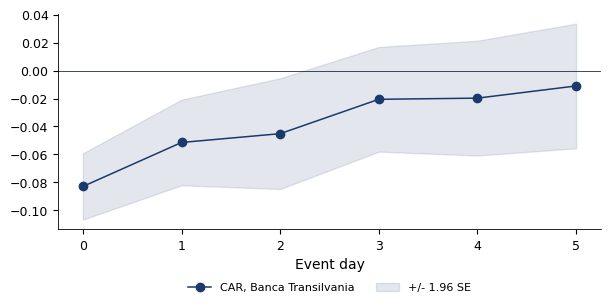

In [ ]:
from scipy import stats
mkt = fetch_daily('BET', 'market', 'close', start='2017-01-01')
def event(name):
    r = np.log(pd.concat([load(name, start='2017-01-01'), mkt], axis=1, keys=['i', 'm']).dropna()).diff().dropna()
    t0 = r.index.get_loc(pd.Timestamp('2018-12-19')); est, ev = r.iloc[t0 - 250:t0 - 10], r.iloc[t0:t0 + 6]
    X = np.column_stack([np.ones(len(est)), est['m']]); b = np.linalg.lstsq(X, est['i'], rcond=None)[0]
    sig = (est['i'] - X @ b).std(ddof=2); pred = b[0] + b[1] * ev['m']; ar = ev['i'] - pred; L, T = len(ar), len(est)
    mb, Smm = est['m'].mean(), ((est['m'] - est['m'].mean()) ** 2).sum()
    se0 = sig * np.sqrt(1 + 1 / T + (ev['m'].iloc[0] - mb) ** 2 / Smm)          # prediction-error variances (MacKinlay, 1997)
    seC = sig * np.sqrt(L + L ** 2 / T + (ev['m'].sum() - L * mb) ** 2 / Smm)
    pv = lambda z: 2 * stats.t.sf(abs(z), T - 2)
    print(f'{name}: estimation window {est.index[0].date()} - {est.index[-1].date()} (T = {T}); a = {b[0]:.4%} a day, b = {b[1]:.3f}, '
          f'sigma_e = {sig:.3%}, mean r_m = {mb:.3%}, S_mm = {Smm:.5f}')
    tab = pd.DataFrame({'r_i': ev['i'], 'r_m': ev['m'], 'predicted': pred, 'AR': ar}); tab.index = [f'{k} ({d.date()})' for k, d in enumerate(ev.index)]
    print((100 * tab).round(2).to_string(), f'\nCAR[0,+5] = {ar.sum():.2%}')
    print(f'AR_0: leverage (r_m0 - mean)^2/S_mm = {(ev["m"].iloc[0] - mb) ** 2 / Smm:.3f}, SE {se0:.2%}, t = {ar.iloc[0] / se0:.2f}, p = {pv(ar.iloc[0] / se0):.1e}; '
          f'CAR: SE {seC:.2%}, t = {ar.sum() / seC:.2f}, p = {pv(ar.sum() / seC):.2f}')
    print(f'as price changes: r_i day 0 {np.expm1(ev["i"].iloc[0]):.2%}, BET {np.expm1(ev["m"].iloc[0]):.2%}, AR_0 as a price relative {np.expm1(ar.iloc[0]):.2%}')
    return ar, sig, T, L, mb, Smm, ev
ar, sig, T, L, mb, Smm, ev = event('Banca Transilvania')
se_path = [sig * np.sqrt(l + l ** 2 / T + (ev['m'].iloc[:l].sum() - l * mb) ** 2 / Smm) for l in range(1, L + 1)]
car = np.cumsum(ar.values); fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(range(6), car, 'o-', color=MainBlue, label='CAR, Banca Transilvania')
ax.fill_between(range(6), car - 1.96 * np.array(se_path), car + 1.96 * np.array(se_path), color=MainBlue, alpha=0.12, label='+/- 1.96 SE')
ax.axhline(0, color=Gray, lw=0.6); ax.set_xlabel('Event day'); legend_outside_bottom(ax, ncol=2, y=-0.2); plt.show()

**Interpretare (soluție).** Ziua 0 este o surpriză mare, dar AR-urile din zilele 1–3 inversează cea mai mare parte a ei: CAR-ul pe șase zile nu este semnificativ. BET a scăzut cu 11.2% (randament logaritmic −11.9%): modelul de piață elimină cea mai mare parte a șocului, deci AR-ul (−8.3% în termeni logaritmici, aproximativ −8.0% ca raport de prețuri) este relativ la piață, nu pierderea totală de preț a băncii, de 19.9% (logaritmic −22.2%); un benchmark fără bănci ar evita această contaminare. Cu una sau șase erori non-Normale, referința $t$ este aproximativă.

### B8 [Propus]. Același eveniment pentru BRD <a id="B8"></a>

**Model:** B7 [Rezolvat]; refolosiți funcția de acolo, se schimbă doar simbolul. **Date:** BRD (adjusted close) și indicele BET; aceleași ferestre ca în B7.

1. Raportați $\hat b$, $\hat\sigma_\varepsilon$, tabelul AR și $CAR[0,+5]$ cu $t$ și $p$.
2. Construiți un tabel pentru cele două bănci: $AR_0$, statistica $t$ bazată pe eroarea de predicție, $CAR$ și statistica sa $t$.
3. Reprezentați pe un singur grafic cele două traiectorii CAR cu benzi de ±1.96 SE.
4. Care bancă a fost lovită mai puternic în raport cu volatilitatea ei normală? Folosiți ca statistică de comparație $t$-ul lui $AR_0$ bazat pe eroarea de predicție.

**Interpretare.** Inversarea poate însemna o reacție exagerată (overreaction) sau o politică retrasă parțial; ce dovezi datate ar putea separa cele două explicații?

In [ ]:
# Your code here

### B9 [Propus]. BET-TR în RON și în EUR <a id="B9"></a>

**Model:** B2 [Rezolvat] (conversia valutară). **Date:** indicele BET-TR (close) și cursul BNR EUR/RON $S_t$ (RON per EUR), prețuri îmbinate în zilele comune, 5 ian. 2015 – 18 sep. 2026.

1. Convertiți: $P^{EUR}_t = P^{RON}_t/S_t$; lucrați pas cu pas pentru o dată (13 aug. 2025).
2. Arătați că $r^{EUR}_t = r^{RON}_t - \Delta s_t$, cu $s_t = \ln S_t$.
3. Calculați CAGR și volatilitatea ($q = n/Y$ observat pentru prețurile îmbinate) în RON și în EUR, precum și corelația dintre $r^{RON}$ și $\Delta s$.
4. Reprezentați grafic ambele traiectorii ale averii.

**Raportați:** cele două CAGR, cele două volatilități, corelația, graficul. **Interpretare:** pentru un investitor în euro, deprecierea leului este o frînă a randamentului, un risc sau ambele?

In [ ]:
# Your code here

### B9 extins [Propus]. Este semnificativ efectul valutar? <a id="B9x"></a>

**Model:** B2 extins și B7 [Rezolvat]. **Date:** B9, $n = 2925$ randamente din zilele comune, $q = n/Y$ intervale observate pe an, din prețurile îmbinate din B9.

1. Arătați că $\operatorname{Var}(r^{EUR}) = \operatorname{Var}(r^{RON}) + \operatorname{Var}(\Delta s) - 2\operatorname{Cov}(r^{RON}, \Delta s)$; raportați fiecare termen anualizat (×$q$) în unități zecimale, apoi extrageți rădăcinile pătrate.
2. Regresați $r^{RON}_t$ pe o constantă și pe $\Delta s_t$, cu standard errors HAC Newey–West (Newey și West, 1987, $L = 8$); raportați panta, $t$ și $p$; adăugați un interval de 95% prin bootstrap staționar pentru corelație (`default_rng(42)`).
3. Estimați drift-ul logaritmic anual al leului, $q \times$ media lui $\Delta s_t$, cu SE HAC, $t$ și intervalul de 95%.
4. Arătați că $\ln(1 + CAGR^{RON}) - \ln(1 + CAGR^{EUR}) = \ln(S_{end}/S_{start})/Y$, adică drift-ul de la (3).

**Interpretare.** Ipoteza testată la (3) este „drift logaritmic zero”.
- Este diferența dintre cele două CAGR obținute de voi în B9 distinctă statistic de zero?
- Ar face un investitor în euro hedging pentru riscul leului?

In [ ]:
# Your code here

### B1 extins [Propus]. Filtrul Hampel standard <a id="B1x"></a>

**Model:** B1 audit complet [Rezolvat]. **Metodă:** filtrul Hampel standard, [Pearson, Neuvo, Astola și Gabbouj (2016)](https://doi.org/10.1186/s13634-016-0383-6), Secțiunea 2, ec. (1)–(4): fereastra $x_{k-K}, \dots, x_{k+K}$ cu $K = 5$ (11 cotații, ca în Secțiunile 5–6 ale lucrării); $m_k$ = mediana ferestrei, $S_k = 1.4826 \times \operatorname{median}_j |x_{k-j} - m_k|$; $x_k$ este marcată dacă $|x_k - m_k| > t\,S_k$; primele și ultimele 5 cotații nu sînt testate. **Date:** BNR EUR/RON 2015–2026 (referință curată) și seria de piață din zilele lucrătoare din B1 audit complet.

1. Parcurgeți pas cu pas fereastra din jurul datei de 13 aug. 2025: $m_k$, MAD, $S_k$ și $|x_k - m_k|/S_k$; pentru ce valori ale lui $t$ este marcată cotația?
2. Pe seria BNR: proporția ferestrelor de implozie ($S_k = 0$, Secțiunea 3 a lucrării) și proporția zilelor marcate pe grila din lucrare $t = 0, 0.5, \dots, 21$ (Secțiunea 5.2), cu un grafic; comparați limita din ec. (8) a lucrării cu cea mai mare valoare $|x_k - m_k|/S_k$.
3. Pe seria de piață, aplicați $t = 2$ (Secțiunea 6 a lucrării) și $t = 5$ (Secțiunea 5.2): cotațiile marcate, suprapunerea cu cele 11 cotații marcate și cele 9 erori din B1 audit complet, volatilitatea după eliminarea cotațiilor marcate.

**Interpretare.**
- De ce MAD și de ce 1.4826?
- Ce se întîmplă într-o fereastră de implozie?
- Poate un prag să înlocuiască verificarea cu BNR din B1?

In [ ]:
# Your code here

## Pachetul 7: Stablecoins <a id="pack7"></a>

B10, B10 extins. Cerințe preliminare: A2–A3, B7.

### B10 [Propus]. Creșterea stablecoin-urilor <a id="B10"></a>

**Model:** A2–A3 și B2 [Rezolvat]. **Date:** DefiLlama, valoarea totală zilnică în circulație a stablecoin-urilor ancorate la USD, împărțită la $10^9$ (mld. USD), 31 dec. 2019 – 18 sep. 2026.

1. Extrageți valorile de la sfîrșitul anilor 2019–2025 și creșterea pe fiecare an calendaristic; raportați separat 2026, ca o creștere de la începutul anului (year-to-date) pînă la 18 sep.
2. Găsiți vîrful din 2022 și minimul care a urmat, pînă la sfîrșitul lui 2023, cu datele lor, precum și variația de la vîrf la minim.
3. Calculați CAGR de la 1 ian. 2020 la 18 sep. 2026, cu valorile exacte de la capete.
4. Reprezentați grafic seria împreună cu punctele de la sfîrșit de an.

**Interpretare.** Oferta (supply) este o valoare în USD aflată în circulație, nu un preț; poate ea să scadă fără ca vreun token să fie ars (burned)?

In [ ]:
# Your code here

### B10 extins [Propus]. A schimbat prăbușirea Terra regimul de creștere? <a id="B10x"></a>

**Model:** B7 [Rezolvat] (regresia OLS și testul ei $t$). **Date:** $g_t = \Delta\ln(\text{supply}_t)$, 2 ian. 2020 – 18 sep. 2026, $n = 2452$; prăbușirea Terra la 9 mai 2022.

1. Dată cunoscută (Chow, 1960): $g_t = a + b\,D_t + e_t$, $D_t = 1\{t \ge \text{9 May 2022}\}$, SE HAC (Newey și West, 1987, $L = 8$); raportați $a$, $b$ (anualizate ×365) și $t$.
2. Dată necunoscută (Andrews, 1993): statistica Wald HAC pentru fiecare dată din zona centrală de 70% (3 ian. 2021 – 15 sep. 2025); comparați maximul ei cu 8.85, valoarea critică de 5% pentru această trunchiere (trimming).
3. Data estimată prin cele mai mici pătrate: data care minimizează suma pătratelor reziduurilor; reprezentați grafic profilurile Wald și SSR.
4. Verificați varianța reziduurilor înainte și după dată și spuneți dacă poate fi raportat intervalul de încredere pentru data rupturii din Bai (1997), care presupune aceeași distribuție a erorilor în ambele regimuri.

**Interpretare.**
- A început încetinirea odată cu Terra?
- Este ruptura în nivelul ofertei sau în drift-ul ei?

In [ ]:
# Your code here

## Pachetul 8: Laborator de investiții pasive <a id="pack8"></a>

C3. Cerințe preliminare: studiul de caz din curs, Pachetul 2.

### C3 [Propus]. Investițiile pasive și elasticitatea cererii <a id="C3"></a>

**Model:** studiul de caz din curs ([Haddad, Huebner și Loualiche, 2025](https://doi.org/10.1257/aer.20230505)) și B2 extins [Rezolvat]. **Întrebare:** este pass-through-ul de o treime din articol robust în raport cu cine anume trece la investiții pasive?

**Notații.** Acțiunea $k$, investitorul activ $i$; $w_{ik}$ = numărul de acțiuni deținute de $i$ ca fracțiune din totalul acțiunilor lui $k$; ponderea activă $A_k = \sum_i w_{ik}$; elasticitatea proprie $\bar{\mathcal{E}}_{ik}$; $\chi$: intensitatea răspunsului strategic, adică cît de mult reacționează cererea investitorilor la elasticitatea celorlalți investitori în acțiunea respectivă (Tabelul 2, rîndul 1: $\chi = 2.97$); elasticitatea agregată (nota de subsol 53) $\mathcal{E}_{agg,k} = \sum_i w_{ik}\bar{\mathcal{E}}_{ik}/(1 + \chi A_k)$.

**Exercițiu de încălzire cu doi investitori:** $w_1 = 0.4$ cu $\bar{\mathcal{E}}_1 = 1$, $w_2 = 0.3$ cu $\bar{\mathcal{E}}_2 = 3$, $\chi = 2.97$; ponderea activă scade de la 0.70 la 0.60: 0.1 din totalul acțiunilor devine pasiv.
1. Calculați $\mathcal{E}_{agg}$ înainte de trecere și după trecere: cînd ambii își reduc proporțional deținerile, cînd trece investitorul 2 (elastic), cînd trece investitorul 1.
2. Comparați fiecare raport $\Delta\log\mathcal{E}_{agg}/\Delta\log A$ cu $1/(1 + \chi A) = 0.325$ la ponderea activă inițială $A=0.70$ (un exemplu ipotetic, diferit de media în timp de 0.68 din articol). Aici $A$ desemnează ponderea activă, notată $\alpha$ în slide-uri, nu factorul de anualizare.

**Date:** FRED `BOGZ1LM563064100Q` (acțiunile corporative deținute de ETF-uri) raportat la `BOGZ1LM893064105Q` (toate sectoarele), 2001 Q1 – 2026 Q2.

3. Ponderea ETF-urilor în 2001 Q1, 2020 Q4, 2026 Q2 și variațiile implicite, cu 81% activ în 2001 și un pass-through de 0.33. Explicați de ce această pondere a ETF-urilor nu este ponderea pasivă din articol: include ETF-urile active și omite fondurile mutuale indexate.

**Simulare** (codul de pornire de mai jos, `numpy.random.default_rng(seed)`):

4. 2,000 de acțiuni: $A_k \sim U(0.55, 0.85)$; 40 de investitori activi pentru fiecare acțiune, cu $w_{ik} = A_k \times$ ponderi extrase din distribuția Dirichlet(1, …, 1) (uniformă pe simplexul 40-dimensional); $\bar{\mathcal{E}}_{ik}$ log-Normală cu mediana 1.6 și abaterea standard logaritmică 0.6; $\chi = 2.97$.
5. În fiecare acțiune, o fracțiune $f_k \sim U(0, 0.2)$ din $A_k$ devine pasivă după trei reguli: toți proporțional; cei mai elastici primii; cei mai puțin elastici primii (deținerile întregi, în ordine, ultima parțial, pînă se atinge $f_k A_k$).
6. Regresați $\Delta\log\mathcal{E}_{agg,k}$ pe o constantă și pe $\Delta\log A_k$ (Tabelul 4, coloana 1).
7. Repetați pentru seed-urile 1–10, cu aceleași extrageri pentru toate regulile, și pentru $\chi = 0$.

**Raportați:** ponderile ETF și variațiile implicite; un tabel al pantelor (media, minimul, maximul pe seed-uri) alături de media lui $1/(1 + \chi A_k)$. Intervalul dat de seed-uri reflectă variabilitatea simulării, nu este un interval de încredere de eșantionare. **Interpretare:**
- De ce este panta egală cu o treime doar atunci cînd cei care trec la pasiv sînt reprezentativi?
- Cum trebuie citită valoarea de 11% din articol dacă investitorii cei mai elastici ar fi trecut primii la pasiv?

In [ ]:
def c3_run(seed, chi=2.97, K=2000, N=40, mode='rep'):
    """Simulated cross-section: K stocks, N active investors each; A_k = active share of stock k (fraction of all shares),
    w_ik = holdings of investor i in stock k as a fraction of all shares (sum_i w_ik = A_k),
    E_agg,k = sum_i w_ik Ebar_ik / (1 + chi A_k) (footnote 53); a fraction f_k of A_k turns passive under a rule."""
    rng = np.random.default_rng(seed)
    A = rng.uniform(0.55, 0.85, K); f = rng.uniform(0, 0.2, K)
    dlE, dlA, pt, E0s = np.empty(K), np.empty(K), np.empty(K), np.empty(K)
    for k in range(K):
        s = rng.dirichlet(np.ones(N)) * A[k]; e = np.exp(np.log(1.6) + 0.6 * rng.standard_normal(N))
        E0 = (s * e).sum() / (1 + chi * A[k]); target = f[k] * A[k]
        if mode == 'rep':
            sw = f[k] * s
        else:
            order = np.argsort(-e) if mode == 'high' else np.argsort(e)
            sw = np.zeros(N); rem = target
            for i in order:
                x = min(s[i], rem); sw[i] = x; rem -= x
                if rem <= 1e-15:
                    break
        A1 = A[k] - sw.sum(); E1 = ((s - sw) * e).sum() / (1 + chi * A1)
        dlE[k] = np.log(E1 / E0); dlA[k] = np.log(A1 / A[k]); pt[k] = 1 / (1 + chi * A[k]); E0s[k] = E0
    X = np.c_[np.ones(K), dlA]; b = np.linalg.lstsq(X, dlE, rcond=None)[0]
    return b[1], pt.mean(), E0s.mean()

In [ ]:
# Your code here